# Predicting Rural Water Point Functionality in East Africa

**Machine Learning Summative Project**

| | |
|---|---|
| **GitHub repository** | _link to be added_ |
| **Google Drive folder** (raw data + model weights) | _link to be added_ |
| **Video presentation** | _link to be added_ |

## Problem statement

About 2.1 billion people worldwide still lack safely managed drinking water (WHO/UNICEF JMP,
2025), and in rural sub-Saharan Africa many depend on community water points such as hand
pumps, protected springs and public tapstands. Reviews of water point data estimate that about
a quarter of hand pumps in sub-Saharan Africa are not working at any given time (Foster et al.,
2020), and authorities often learn about a failure only after a community has already lost
access to safe water.

This project asks: **given the recorded characteristics of a water point (its technology,
water source, age, management, location and the population around it), can we predict
whether water is available at the point?** A reliable classifier would let maintenance
teams prioritise inspections toward the points most likely to be broken.

The task is framed as **binary classification** (`water available: yes / no`) using the
Water Point Data Exchange (WPdx+) dataset for **Uganda, Ethiopia, Kenya and Tanzania**,
with **Rwanda held out entirely** to test whether models transfer to a country they never
saw during training.

## Notebook structure

1. Setup and reproducibility
2. Data loading
3. Exploratory data analysis
4. Preprocessing and feature engineering
5. Traditional machine learning experiments (scikit-learn)
6. Deep learning experiments (TensorFlow / Keras with `tf.data`)
7. Evaluation, error analysis and the Rwanda transfer test
8. Conclusions, limitations and future work

**Runtime:** about 25–35 minutes on a standard Colab CPU runtime (no GPU needed). The longest
steps are the hyperparameter search (Section 5.6) and the learning curves (Section 7.3).

## 1. Setup and reproducibility

The notebook is designed to run top to bottom in **Google Colab**. Colab already ships
with pandas, NumPy, scikit-learn, TensorFlow and Matplotlib; the cell below installs only
what is missing and pins nothing that Colab provides, so the versions actually used are
printed afterwards for the record (they are also listed in `requirements.txt`).

Every source of randomness (Python, NumPy, TensorFlow and hash seeding) is fixed with a
single `SEED` so that splits, model initialisation and results can be reproduced.

In [1]:
# Install packages that Colab does not include by default (quietly).
%pip install -q imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import os
import random
import hashlib
import zipfile
import urllib.request
from pathlib import Path

import numpy as np
import pandas as pd
import tensorflow as tf
import sklearn

SEED = 42


def set_seeds(seed: int = SEED) -> None:
    """Fix every source of randomness used in this notebook."""
    os.environ["PYTHONHASHSEED"] = str(seed)
    random.seed(seed)
    np.random.seed(seed)
    tf.random.set_seed(seed)


set_seeds()
pd.set_option("display.max_columns", 60)

print(f"pandas {pd.__version__} | numpy {np.__version__} | "
      f"scikit-learn {sklearn.__version__} | tensorflow {tf.__version__}")

I0000 00:00:1792496963.237324    7885 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1792496963.272471    7885 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1792496964.314071    7885 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


pandas 2.3.3 | numpy 2.5.3 | scikit-learn 1.9.1 | tensorflow 2.21.0


## 2. Data loading

### Data source

The data comes from the **Water Point Data Exchange Plus (WPdx+)**, a harmonised,
analysis-ready database of rural water points compiled from governments, NGOs and
researchers by the Global Water Challenge. Country extracts are published on the
**Humanitarian Data Exchange (HDX)** under a Creative Commons Attribution licence.
Each row is the most recent observation of one water point.

| Country | HDX dataset | Role in this project |
|---|---|---|
| Uganda | `wpdx_uga` | training / validation / test |
| Ethiopia | `wpdx_eth` | training / validation / test |
| Kenya | `wpdx_ken` | training / validation / test |
| Tanzania | `wpdx_tza` | training / validation / test |
| Rwanda | `wpdx_rwa` | held-out transfer test only |

### How the files are found

HDX updates these files from time to time, so for reproducibility this project uses a
**frozen snapshot** (downloaded on 20 October 2026, HDX version modified 26 July 2026).
The loader looks for the data in this order:

1. CSV files already present in `data/raw/` (for example after a previous run);
2. the zipped snapshot `wpdx_raw_data.zip` in the project's Google Drive folder;
3. a fresh download from HDX.

Every file is checked against the SHA-256 checksum of the snapshot. If HDX has since
published a newer version, the loader still works but prints a warning, because results
may then differ slightly from those in the report.

In [3]:
# Where the raw CSV files live inside the Colab runtime.
DATA_DIR = Path("data/raw")

# Optional: the zipped snapshot in Google Drive (see the README for the shared folder).
USE_GOOGLE_DRIVE = True
DRIVE_ZIP = Path("/content/drive/MyDrive/water-point-functionality/wpdx_raw_data.zip")

# HDX download links and SHA-256 checksums of the frozen snapshot (20 Oct 2026).
HDX_BASE = "https://data.humdata.org/dataset"
SOURCES = {
    "uga": {"country": "Uganda",
            "url": f"{HDX_BASE}/efd21fab-2b22-4328-a30d-ee6ac3a09795/resource/9fa16dfd-dbc3-4735-b7ac-74b489f8d66c/download/wpdx_enhanced.csv",
            "sha256": "5a32da4afe2c959e141666104fd57e741f6e348851a5fb8c3fb5aba2a49d904f"},
    "eth": {"country": "Ethiopia",
            "url": f"{HDX_BASE}/da8746b6-5149-4a67-b5f9-4511dfd6a7ed/resource/af75a56d-c26d-4fa3-989b-feb5a7bd9713/download/wpdx_enhanced.csv",
            "sha256": "8fdee454454bbde77b570c8d2530138ff696a8906df108acb9395d61e3d0391e"},
    "ken": {"country": "Kenya",
            "url": f"{HDX_BASE}/b5744fa0-9312-417f-bcaf-9c75bac95933/resource/b81c8e49-3601-4962-96ee-2c5dc0203df8/download/wpdx_enhanced.csv",
            "sha256": "79062d2463daff90cdb7f1adde5306c59d212f254aa1afc12df8f55e4c08c528"},
    "tza": {"country": "Tanzania",
            "url": f"{HDX_BASE}/dd154b0d-8d0e-421e-8254-e37e38348167/resource/8d998957-fc14-48cc-942e-e3bd0d2fdfd1/download/wpdx_enhanced.csv",
            "sha256": "8b500673e8e4ffef153a7a50514b26583b6895f7e43f98709f9f4a7cba0455fe"},
    "rwa": {"country": "Rwanda",
            "url": f"{HDX_BASE}/be496f2a-db8e-44eb-bd96-851e69771c63/resource/d32e3e02-0997-4dae-804e-d8e4144d151c/download/wpdx_enhanced.csv",
            "sha256": "c9539def678d8641dcc0cfac3bc6d3762f5a9e6584e953ac091cc389a3bcf959"},
}
TRAIN_COUNTRIES = ["uga", "eth", "ken", "tza"]
TRANSFER_COUNTRY = "rwa"

In [4]:
def sha256_of(path: Path) -> str:
    """Return the SHA-256 hex digest of a file, read in 1 MB chunks."""
    digest = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            digest.update(chunk)
    return digest.hexdigest()


def csv_path(code: str) -> Path:
    return DATA_DIR / f"wpdx_water_points_{code}.csv"


def extract_drive_snapshot() -> None:
    """Mount Google Drive (Colab only) and unzip the frozen snapshot into DATA_DIR."""
    if not USE_GOOGLE_DRIVE:
        return
    try:
        from google.colab import drive  # only available inside Colab
    except ImportError:
        return
    if not Path("/content/drive/MyDrive").exists():
        try:
            drive.mount("/content/drive")
        except Exception as err:  # access declined or unavailable
            print(f"Google Drive not mounted ({err}); falling back to the HDX download.")
            return
    if DRIVE_ZIP.exists():
        with zipfile.ZipFile(DRIVE_ZIP) as zf:
            zf.extractall(DATA_DIR)
        print(f"Extracted snapshot from {DRIVE_ZIP}")
    else:
        print(f"No snapshot found at {DRIVE_ZIP}; falling back to HDX download.")


def download_from_hdx(code: str) -> None:
    """Download one country's CSV from HDX."""
    request = urllib.request.Request(SOURCES[code]["url"],
                                     headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(request, timeout=300) as response, \
            open(csv_path(code), "wb") as out:
        out.write(response.read())
    print(f"Downloaded {SOURCES[code]['country']} from HDX")


def ensure_raw_data() -> None:
    """Make sure all five CSV files are in DATA_DIR and match the snapshot checksums."""
    DATA_DIR.mkdir(parents=True, exist_ok=True)
    if not all(csv_path(c).exists() for c in SOURCES):
        extract_drive_snapshot()
    for c, meta in SOURCES.items():
        if not csv_path(c).exists():
            download_from_hdx(c)
        if sha256_of(csv_path(c)) == meta["sha256"]:
            print(f"OK       {meta['country']:<9} checksum matches the snapshot")
        else:
            print(f"WARNING  {meta['country']:<9} differs from the 20 Oct 2026 snapshot "
                  "(HDX has published a newer version); results may differ slightly.")


ensure_raw_data()

OK       Uganda    checksum matches the snapshot
OK       Ethiopia  checksum matches the snapshot
OK       Kenya     checksum matches the snapshot
OK       Tanzania  checksum matches the snapshot
OK       Rwanda    checksum matches the snapshot


### Reading the files

Each HDX file has a second header row containing
[HXL](https://hxlstandard.org/) hashtags (for example `#geo+lat`). These are metadata,
not observations, so the row is skipped; otherwise pandas would read every column as text.
`report_date` is parsed as a date so that the age of each record can be computed later.

In [5]:
def load_country(code: str) -> pd.DataFrame:
    """Read one country's CSV, skipping the HXL hashtag row."""
    df = pd.read_csv(csv_path(code), skiprows=[1], low_memory=False)
    df["report_date"] = pd.to_datetime(df["report_date"], errors="coerce")
    return df


def load_wpdx(codes) -> pd.DataFrame:
    """Load and stack several countries into a single DataFrame."""
    return pd.concat([load_country(c) for c in codes], ignore_index=True)


raw_main = load_wpdx(TRAIN_COUNTRIES)
raw_rwanda = load_wpdx([TRANSFER_COUNTRY])

print(f"Main dataset (UGA, ETH, KEN, TZA): {raw_main.shape[0]:,} rows x {raw_main.shape[1]} columns")
print(f"Rwanda transfer set:               {raw_rwanda.shape[0]:,} rows x {raw_rwanda.shape[1]} columns")

Main dataset (UGA, ETH, KEN, TZA): 162,726 rows x 54 columns
Rwanda transfer set:               6,114 rows x 54 columns


In [6]:
# Sanity checks: one row per water point, and the label distribution per country.
all_raw = pd.concat([raw_main, raw_rwanda], ignore_index=True)
assert all_raw["wpdx_id"].is_unique, "Each water point should appear only once"
assert len(all_raw) >= 20_000, "Raw data must contain at least 20,000 rows"

label_table = pd.crosstab(all_raw["clean_country_name"], all_raw["status_id"], margins=True)
label_table

status_id,No,Unknown,Yes,All
clean_country_name,,,,
Ethiopia,2512,597,21379,24488
Kenya,1915,277,19761,21953
Rwanda,856,313,4945,6114
Tanzania,7601,0,9917,17518
Uganda,16538,2523,79706,98767
All,29422,3710,135708,168840


### What the loaded data shows

The raw data contains **168,840 water points** (162,726 in the four training countries and
6,114 in Rwanda), comfortably above the 20,000-row requirement. Every `wpdx_id` is unique,
so each row is a distinct water point and the same point can never appear in both the
training and test sets.

The target is `status_id`, which records whether **water was available when the point
was last assessed** (`Yes` / `No`). It is the one functionality field that WPdx requires
every contributor to provide, which makes it more reliable than the more detailed
`status_clean` field (explored in the next section). Three observations matter for what
follows:

- **Class imbalance:** roughly 82% of labelled points have water and 18% do not, so
  accuracy alone would be misleading; recall and precision on the *No* class matter most.
- **Countries differ sharply:** Tanzania has a much higher failure share (about 43%) than
  Kenya or Ethiopia (about 9% and 11%), so country and location are likely to be strong signals.
- **Unknown labels:** 3,710 points have `status_id = Unknown`. They carry no label and are
  removed before modelling (Section 4).

## 3. Exploratory data analysis

The goal of this section is to understand the data before any modelling decision is
made: how the label is distributed, which fields are reliable, how much is missing, where
the outliers are, and which columns would leak the answer. Every preprocessing choice in
Section 4 is traced back to a finding here.

All plots in this notebook share one style: the class with water (*functional*) is shown
in blue and the class without water (*not functional*) in orange. Each figure is also saved
to `figures/` so it can be reused in the report.

In [7]:
import re
import matplotlib.pyplot as plt
import matplotlib.ticker as mtick

FIG_DIR = Path("figures")
FIG_DIR.mkdir(exist_ok=True)

# Colour roles (validated colour-blind-safe categorical pair) and neutral ink.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK_2, GRID = "#0b0b0b", "#52514e", "#e4e3df"
CLASS_COLORS = {"Functional": BLUE, "Not functional": ORANGE}

plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "savefig.bbox": "tight",
    "font.size": 10, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.edgecolor": GRID, "axes.labelcolor": INK_2, "xtick.color": INK_2,
    "ytick.color": INK_2, "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.6,
    "axes.spines.top": False, "axes.spines.right": False, "axes.axisbelow": True,
    "legend.frameon": False, "text.color": INK,
})


(FIG_DIR / "report").mkdir(exist_ok=True)


def save_fig(name: str) -> None:
    """Save the current figure to figures/<name>.png and an unnumbered copy for the report
    (figures/report/<name>.png), then show it."""
    fig = plt.gcf()
    fig.savefig(FIG_DIR / f"{name}.png")
    titles = [ax.title for ax in fig.axes] + ([fig._suptitle] if fig._suptitle else [])
    original = [t.get_text() for t in titles]
    for t in titles:
        t.set_text(re.sub(r"^Figure [0-9]+[a-z]?[.] *", "", t.get_text()))
    fig.savefig(FIG_DIR / "report" / f"{name}.png")
    for t, text in zip(titles, original):
        t.set_text(text)
    plt.show()

### 3.1 Defining the target and checking class balance

The target is `status_id`: whether water was available when the point was last visited.
For modelling, the question is turned around so that the class we want to *find* is the
positive class: **`not_functional = 1` when `status_id == "No"`**. Points with an
`Unknown` status carry no label and are set aside.

In [8]:
def add_target(df: pd.DataFrame) -> pd.DataFrame:
    """Keep labelled rows and add the binary target (1 = no water / not functional)."""
    out = df[df["status_id"].isin(["Yes", "No"])].copy()
    out["not_functional"] = (out["status_id"] == "No").astype(int)
    return out


eda = add_target(raw_main)
eda_rwa = add_target(raw_rwanda)

balance = (pd.concat([eda, eda_rwa])
           .groupby("clean_country_name")["not_functional"]
           .agg(points="size", not_functional="sum", failure_rate="mean")
           .sort_values("failure_rate"))
print(f"Labelled points in the four training countries: {len(eda):,} "
      f"(failure rate {eda['not_functional'].mean():.1%})")
print(f"Labelled points in Rwanda (transfer test):      {len(eda_rwa):,} "
      f"(failure rate {eda_rwa['not_functional'].mean():.1%})")
balance.style.format({"points": "{:,}", "not_functional": "{:,}", "failure_rate": "{:.1%}"})

Labelled points in the four training countries: 159,329 (failure rate 17.9%)
Labelled points in Rwanda (transfer test):      5,801 (failure rate 14.8%)


,points,not_functional,failure_rate
clean_country_name,,,
Kenya,"21,676","1,915",8.8%
Ethiopia,"23,891","2,512",10.5%
Rwanda,"5,801",856,14.8%
Uganda,"96,244","16,538",17.2%
Tanzania,"17,518","7,601",43.4%


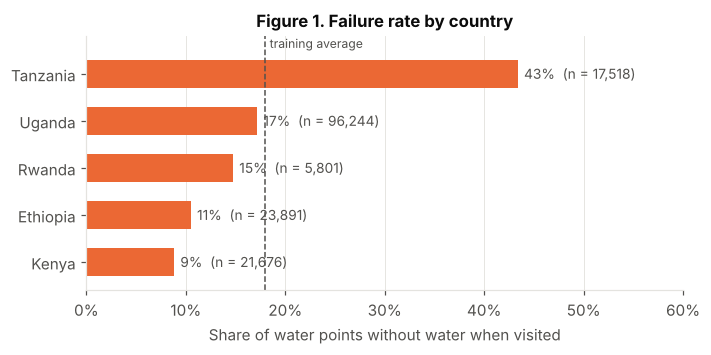

In [9]:
fig, ax = plt.subplots(figsize=(7, 3))
bars = ax.barh(balance.index, balance["failure_rate"], color=ORANGE, height=0.6)
ax.bar_label(bars, labels=[f"{r:.0%}  (n = {n:,})" for r, n in
                           zip(balance["failure_rate"], balance["points"])],
             padding=4, color=INK_2, fontsize=9)
ax.axvline(eda["not_functional"].mean(), color=INK_2, linestyle="--", linewidth=1)
ax.text(eda["not_functional"].mean() + 0.005, len(balance) - 0.45, "training average", color=INK_2, fontsize=8)
ax.set_ylim(-0.6, len(balance) - 0.2)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, 0.6)
ax.set_xlabel("Share of water points without water when visited")
ax.set_title("Figure 1. Failure rate by country")
ax.grid(axis="y", visible=False)
save_fig("fig01_failure_rate_by_country")

**Interpretation.** About **18%** of labelled water points in the training countries had no
water when visited, so the problem is moderately imbalanced: a model that always predicts
"functional" would already be 82% accurate while finding none of the broken points. This is
why the evaluation in later sections focuses on recall, precision, F1 and the area under the
precision-recall curve for the *not functional* class rather than accuracy.

The failure rate also differs sharply between countries, from about 9% in Kenya to 43% in
Tanzania. Part of this is real (differences in technology, age and maintenance systems), but
part is likely to reflect *who collected the data and how*: different surveys and
organisations visit different kinds of points. Rwanda, held out for the transfer test, sits
at about 15%, close to the training average.

### 3.2 Why `status_id` and not the detailed `status_clean` field

WPdx also provides a more detailed status (`status_clean`) with categories such as
*Functional, needs repair* and *Non-Functional, dry season*. A three-class target built from
it would seem richer, so the two fields are cross-tabulated to check that they agree.

In [10]:
conflict = pd.crosstab(eda["status_clean"], eda["status_id"])
conflict["share_with_water"] = conflict["Yes"] / conflict.sum(axis=1)
conflict.sort_values("share_with_water").style.format(
    {"No": "{:,}", "Yes": "{:,}", "share_with_water": "{:.1%}"})

status_id,No,Yes,share_with_water
status_clean,,,
Abandoned/Decommissioned,752,55,6.8%
"Non-Functional, dry season","4,876","1,521",23.8%
Non-Functional,"22,286","48,582",68.6%
Others,14,35,71.4%
Functional,342,"9,579",96.6%
"Functional, needs repair",284,"63,886",99.6%
"Functional, not in use",12,"7,105",99.8%


In [11]:
nonfunc = eda[eda["status_clean"] == "Non-Functional"]
print("Points labelled 'Non-Functional' in status_clean that nevertheless had water (status_id = Yes):")
print(nonfunc.groupby("clean_country_name")["status_id"]
      .apply(lambda s: f"{(s == 'Yes').sum():,} of {len(s):,} ({(s == 'Yes').mean():.0%})").to_string())

Points labelled 'Non-Functional' in status_clean that nevertheless had water (status_id = Yes):
clean_country_name
Ethiopia    21,377 of 23,363 (91%)
Kenya       11,571 of 13,302 (87%)
Tanzania      5,697 of 8,640 (66%)
Uganda       9,937 of 25,563 (39%)


**Interpretation.** The detailed field is not consistent with the basic one. Of the
roughly 71,000 points marked *Non-Functional* in `status_clean`, about 48,600 (69%) are
recorded as having water in `status_id`. The contradiction is worst in Ethiopia (91% of
"Non-Functional" points have water) and Kenya (87%), and smaller in Uganda (39%), which
suggests that contributors mapped their own categories onto the WPdx standard in different
ways. Because `status_id`
is the single functionality field that every contributor must supply, it is the more
trustworthy label, and this project therefore uses a **binary** target. `status_clean` is
excluded from the features since it is another encoding of the outcome. This label noise is
revisited as a limitation in the Discussion.

### 3.3 Missing values

Many WPdx fields are optional, so missing values are expected. Two questions matter: *how
much* is missing, and *whether missingness itself is related to failure* (in which case
simply dropping or imputing would throw information away).

In [12]:
CANDIDATE_FIELDS = ["water_source_clean", "water_tech_clean", "management_clean", "pay_clean",
                    "install_year", "local_population", "clean_adm4", "installer",
                    "subjective_quality", "fecal_coliform_presence", "rehab_priority",
                    "would_gain_access"]

missing = pd.DataFrame({
    "missing_share": eda[CANDIDATE_FIELDS].isna().mean(),
    "failure_rate_if_missing": [eda.loc[eda[c].isna(), "not_functional"].mean() for c in CANDIDATE_FIELDS],
    "failure_rate_if_present": [eda.loc[eda[c].notna(), "not_functional"].mean() for c in CANDIDATE_FIELDS],
}).sort_values("missing_share")
missing.style.format("{:.1%}")

,missing_share,failure_rate_if_missing,failure_rate_if_present
water_source_clean,9.5%,17.5%,18.0%
local_population,11.5%,19.5%,17.7%
management_clean,16.8%,11.3%,19.3%
install_year,17.8%,13.0%,19.0%
water_tech_clean,36.2%,14.2%,20.0%
clean_adm4,39.6%,19.1%,17.2%
pay_clean,63.6%,15.4%,22.3%
subjective_quality,80.6%,14.5%,32.3%
installer,81.3%,14.5%,33.0%
would_gain_access,83.0%,1.1%,100.0%


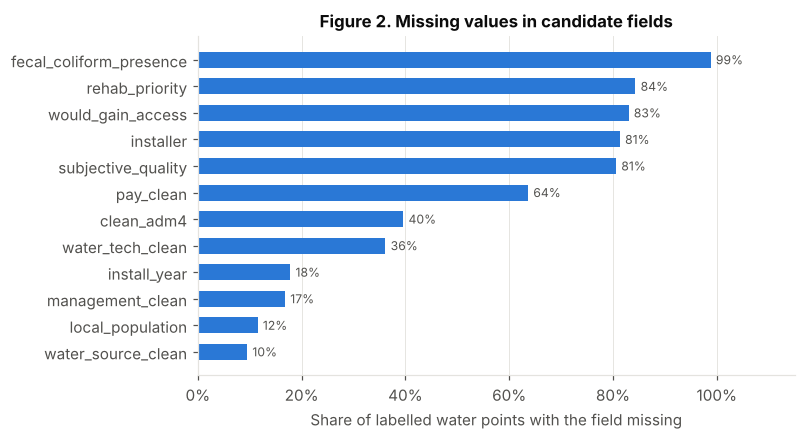

In [13]:
fig, ax = plt.subplots(figsize=(7, 4))
y = np.arange(len(missing))
ax.barh(y, missing["missing_share"], color=BLUE, height=0.6)
ax.set_yticks(y, missing.index)
ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_xlim(0, 1.15)
for yi, share in zip(y, missing["missing_share"]):
    ax.text(share + 0.01, yi, f"{share:.0%}", va="center", fontsize=8, color=INK_2)
ax.set_xlabel("Share of labelled water points with the field missing")
ax.set_title("Figure 2. Missing values in candidate fields")
ax.grid(axis="y", visible=False)
save_fig("fig02_missing_values")

**Interpretation.** Missingness ranges from almost none to almost total, and it is clearly
*informative*. Points with no recorded install year fail less often (13%) than points with
one (19%), and points with no recorded technology or management type also fail less often.
These fields were most likely left blank by particular contributors rather than at random,
so for the usable fields the model receives an explicit **"was missing" flag** alongside the
imputed value (Section 4).

The table also exposes two **leakage** fields: `rehab_priority` and `would_gain_access` are
present *only* for broken points (failure rate 100% when present). They are outputs of
WPdx's repair-prioritisation tool, which is only run on non-functional points, so they encode
the answer and must be removed. Water-quality fields (`subjective_quality`,
`fecal_coliform_presence`) are measured *on the water itself* and are therefore only
available after visiting a working point; they are excluded too. `installer` (82% missing,
hundreds of free-text spellings) and `clean_adm4` are dropped as too sparse.

### 3.4 Install year, age and outliers

The age of a water point is expected to be one of the strongest predictors of failure:
pumps wear out and spare parts become harder to find. Age is not stored directly, but it can
be derived from `install_year` and the date of the visit (`report_date`).

In [14]:
report_year = eda["report_date"].dt.year
install = eda["install_year"]
print(f"install_year range: {install.min():.0f} to {install.max():.0f}")
print(f"  installed before 1950 (placeholder values such as 1900): {(install < 1950).sum():,}")
print(f"  installed after the visit that recorded them:            {(install > report_year).sum():,}")

age_at_visit = (report_year - install).where((install >= 1950) & (install <= report_year))
eda["age_at_visit"] = age_at_visit
print(f"\nAge at visit (years), valid values only: median {age_at_visit.median():.0f}, "
      f"90th percentile {age_at_visit.quantile(0.9):.0f}")

install_year range: 1900 to 2050
  installed before 1950 (placeholder values such as 1900): 314
  installed after the visit that recorded them:            52

Age at visit (years), valid values only: median 8, 90th percentile 21


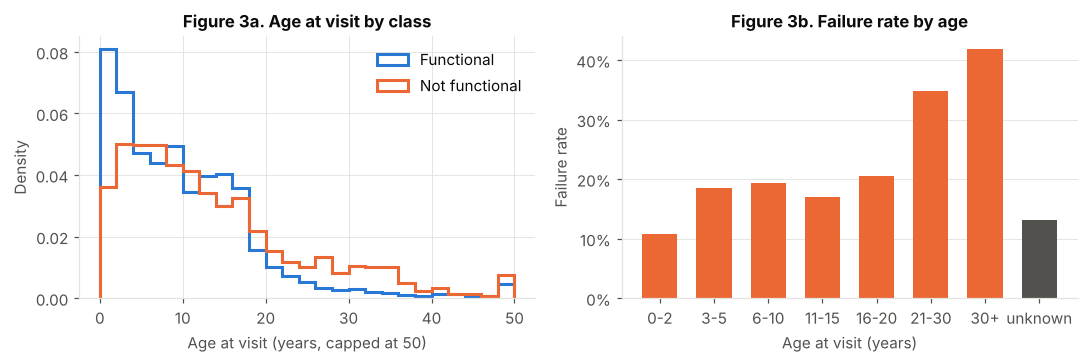

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3.4))
bins = np.arange(0, 51, 2)
for label, colour, name in [(0, BLUE, "Functional"), (1, ORANGE, "Not functional")]:
    values = eda.loc[eda["not_functional"] == label, "age_at_visit"].dropna()
    axes[0].hist(values.clip(upper=50), bins=bins, density=True, histtype="step",
                 linewidth=2, color=colour, label=name)
axes[0].set_xlabel("Age at visit (years, capped at 50)")
axes[0].set_ylabel("Density")
axes[0].set_title("Figure 3a. Age at visit by class")
axes[0].legend()

age_bins = pd.cut(eda["age_at_visit"], [-1, 2, 5, 10, 15, 20, 30, 200],
                  labels=["0-2", "3-5", "6-10", "11-15", "16-20", "21-30", "30+"])
rate = eda.groupby(age_bins, observed=True)["not_functional"].mean()
missing_rate = eda.loc[eda["age_at_visit"].isna(), "not_functional"].mean()
rate.loc["unknown"] = missing_rate
axes[1].bar(rate.index.astype(str), rate.values,
            color=[ORANGE] * (len(rate) - 1) + [INK_2], width=0.65)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[1].set_xlabel("Age at visit (years)")
axes[1].set_ylabel("Failure rate")
axes[1].set_title("Figure 3b. Failure rate by age")
axes[1].grid(axis="x", visible=False)
plt.tight_layout()
save_fig("fig03_age_at_visit")

**Interpretation.** `install_year` contains clear data-entry errors: several hundred points
are dated before 1950 (mostly the placeholder 1900) and some were apparently installed *after*
the visit that recorded them. These values are treated as missing rather than deleted, so the
rest of each record is kept.

Once cleaned, age behaves as expected, though not linearly. About 11% of points under three
years old are dry; the rate then sits on a plateau of roughly 17–20% between 3 and 20 years,
and rises sharply after that, to 35% for points aged 21–30 and 42% for points over 30. A
threshold pattern like this is easy for tree ensembles to capture and hard for a linear model
on raw age, which motivates comparing both families. The grey bar shows that points with *unknown* age
fail less often than average, confirming that the missing-value flag carries signal.

### 3.5 Technology, management and payment

These are the attributes that a water authority can actually change, so they matter for
interpretation as well as prediction.

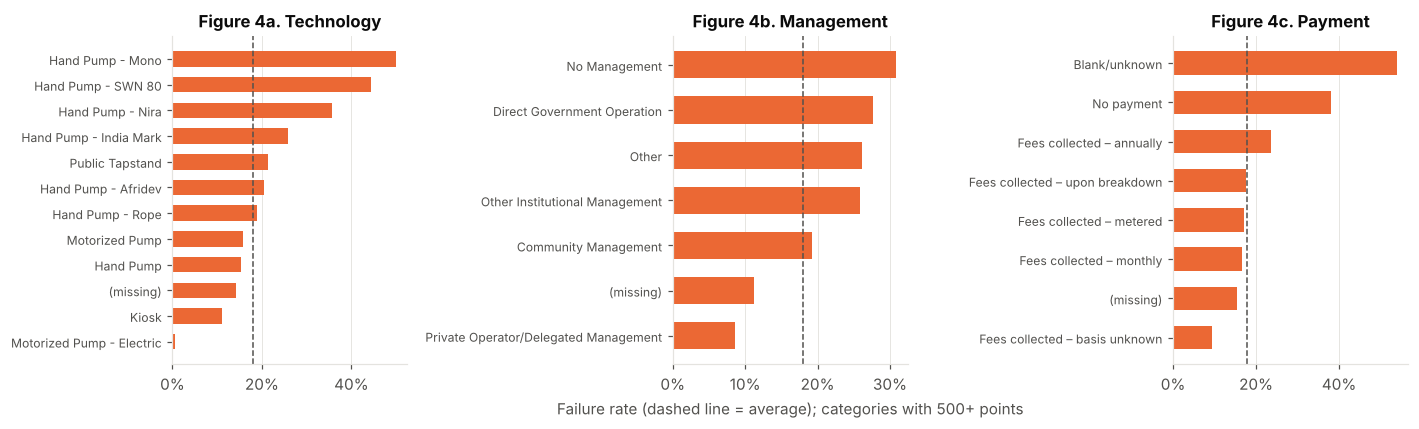

In [16]:
def failure_by(col: str, min_count: int = 500, top: int = 15) -> pd.DataFrame:
    """Failure rate per category (categories with at least `min_count` points)."""
    g = (eda.assign(**{col: eda[col].fillna("(missing)")})
         .groupby(col)["not_functional"].agg(points="size", failure_rate="mean"))
    return g[g["points"] >= min_count].sort_values("failure_rate").tail(top)


fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, col, title in [(axes[0], "water_tech_clean", "Figure 4a. Technology"),
                       (axes[1], "management_clean", "Figure 4b. Management"),
                       (axes[2], "pay_clean", "Figure 4c. Payment")]:
    g = failure_by(col)
    ax.barh(g.index, g["failure_rate"], color=ORANGE, height=0.6)
    ax.axvline(eda["not_functional"].mean(), color=INK_2, linestyle="--", linewidth=1)
    ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
    ax.set_title(title)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", labelsize=8)
axes[1].set_xlabel("Failure rate (dashed line = average); categories with 500+ points")
plt.tight_layout()
save_fig("fig04_failure_by_category")

**Interpretation.** Technology matters a great deal. Electric motorised pumps almost never
appear as dry (under 1%), whereas some hand-pump models fail far more often than average
(*Mono* about 50%, *SWN 80* about 44%, *Nira* about 36%). This is consistent with the
engineering literature on hand-pump reliability and spare-parts supply chains.

Management and payment tell a similar story about *who looks after the point*. Points run by
private operators fail least often, while points with no management fail most often. Points
where users pay nothing fail about twice as often (38%) as points where fees are collected
monthly or by meter (about 17%).
The payment category labelled *Blank/unknown* has the highest failure rate of all (54%),
another sign that how a field was filled in is related to the outcome.

### 3.6 When the data was collected

Each row is the *latest* visit to a water point, but those visits span two decades and come
from many separate survey campaigns.

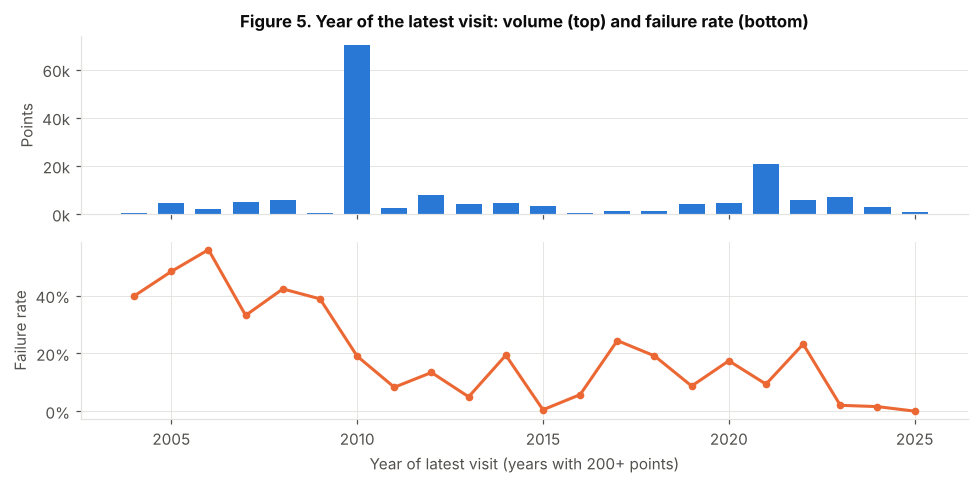

In [17]:
by_year = eda.groupby(eda["report_date"].dt.year)["not_functional"].agg(points="size", failure_rate="mean")
by_year = by_year[by_year["points"] >= 200]

fig, axes = plt.subplots(2, 1, figsize=(9, 4.5), sharex=True, height_ratios=[1, 1])
axes[0].bar(by_year.index, by_year["points"], color=BLUE, width=0.7)
axes[0].set_ylabel("Points")
axes[0].yaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
axes[0].set_title("Figure 5. Year of the latest visit: volume (top) and failure rate (bottom)")
axes[0].grid(axis="x", visible=False)
axes[1].plot(by_year.index, by_year["failure_rate"], color=ORANGE, linewidth=2, marker="o", markersize=4)
axes[1].yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
axes[1].set_ylabel("Failure rate")
axes[1].set_xlabel("Year of latest visit (years with 200+ points)")
plt.tight_layout()
save_fig("fig05_report_year")

**Interpretation.** The data is dominated by a few large campaigns, most visibly the 2010
national survey in Uganda (about 70,000 points). The failure rate of points last visited in the
mid-2000s is far higher than for points visited recently. This partly reflects real
deterioration (a point last checked long ago has had more time to break and was perhaps never
revisited *because* it broke), but it also reflects survey design. The year of the visit is
kept as a feature, and the Discussion treats this temporal structure as a limitation: a model
trained on these snapshots learns the conditions of past campaigns, not only the physics of
pump failure.

### 3.7 Location

Water points cluster geographically, and failure rates are known to vary between districts
because of geology, groundwater depth and the strength of local maintenance systems.

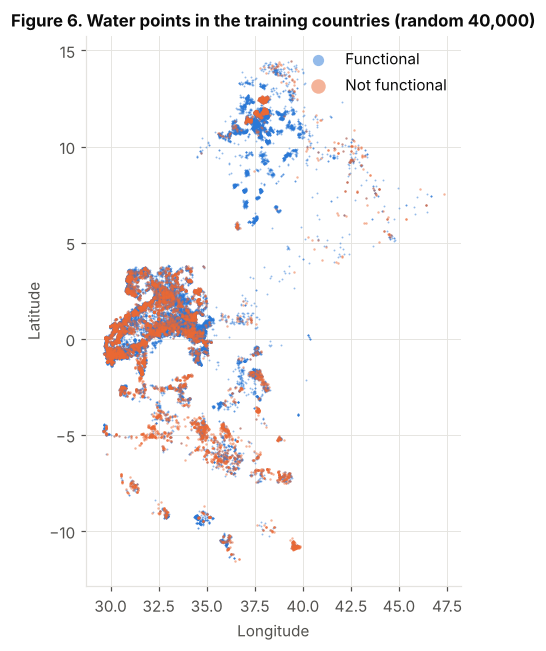

In [18]:
sample = eda.sample(40_000, random_state=SEED)
fig, ax = plt.subplots(figsize=(6.5, 6.5))
for label, colour, name, size in [(0, BLUE, "Functional", 1.5), (1, ORANGE, "Not functional", 2.5)]:
    s = sample[sample["not_functional"] == label]
    ax.scatter(s["lon_deg"], s["lat_deg"], s=size, color=colour, alpha=0.5, linewidths=0, label=name)
ax.set_aspect("equal")
ax.set_xlabel("Longitude")
ax.set_ylabel("Latitude")
ax.set_title("Figure 6. Water points in the training countries (random 40,000)")
ax.legend(markerscale=6, loc="upper right")
save_fig("fig06_map")

**Interpretation.** Broken points are not scattered at random: they form visible clusters
(for example in parts of Tanzania and northern Uganda). Location is therefore informative,
and coordinates plus administrative region are used as features. This clustering also has a
consequence for evaluation: with a random split, neighbouring points from the same survey end
up in both the training and the test set, which can make test scores optimistic. The Rwanda
transfer test (Section 7) is the check against that optimism.

### 3.8 Who collected the data

The `source` column names the organisation that contributed each record.

In [19]:
src = eda.groupby("source")["not_functional"].agg(points="size", failure_rate="mean")
src[src["points"] >= 3000].sort_values("failure_rate").style.format(
    {"points": "{:,}", "failure_rate": "{:.1%}"})

,points,failure_rate
source,,
Evidence Action,"14,333",1.2%
COWASH,"13,389",1.3%
Virtual Kenya,"3,174",10.6%
"Ministry of Water and Environment, Uganda","77,048",17.4%
USAID/KEA KIWASH,"6,502",17.7%
Amhara Region,"3,106",23.1%
The Water Trust,"3,580",27.1%
SNV,"3,970",40.7%
WaterAid,"10,975",46.1%


**Interpretation.** Failure rates by contributor range from about 1% (Evidence Action, COWASH)
to about 46% (WaterAid). These differences mostly reflect *what each organisation monitors*
(for instance, Evidence Action records points where it maintains chlorine dispensers, which are
by definition in use) rather than anything about the water points themselves. A model given
`source` could score well by learning which survey a row came from, a classic shortcut that
would not help a ministry predicting failures in a new survey. `source` is therefore excluded
from the main feature set, and Experiment ML-8 measures how much it would inflate the scores.

### 3.9 Summary of EDA decisions

| Finding | Decision (Section 4) |
|---|---|
| 18% failure rate, varies 9–43% by country | Report recall, precision, F1, PR-AUC; compare class weighting, resampling and threshold tuning |
| `status_clean` contradicts `status_id` | Binary target from `status_id`; drop `status_clean` |
| `rehab_priority`, `would_gain_access` present only for broken points | Drop (target leakage) |
| Water-quality fields measured only at working points | Drop (post-outcome information) |
| WPdx prediction columns are empty; `criticality`, `pressure`, `assigned_population`, `usage_cap` are outputs of WPdx's own analysis | Drop (empty, or derived by a pipeline that may use functionality) |
| `install_year` has impossible values | Set to missing; derive age at visit |
| Missingness is informative | Median/most-frequent imputation plus "was missing" flags |
| Strong effects of technology, management, payment, age, location, visit year | Keep as features; engineer age, log distances and seasonal terms |
| `source` encodes survey design | Exclude; test its effect in ML-8 |

## 4. Preprocessing and feature engineering

This section turns the raw WPdx records into model-ready features. The steps are written as
small functions so that exactly the same transformation is applied to the training data, the
validation and test sets, and the held-out Rwanda data. Anything *learned* from data (medians
for imputation, category vocabularies, scaling parameters) is learned on the **training split
only**, inside scikit-learn pipelines, so no information from the evaluation data leaks into
the model.

### 4.1 Removing leakage and unusable columns

The columns below are dropped for the reasons established in Section 3.

In [20]:
DROP_COLUMNS = {
    # Other encodings of the outcome
    "status_clean": "detailed status; another encoding of the target",
    # Present only for broken points (outputs of WPdx's repair-priority tool)
    "rehab_priority": "target leakage: only computed for non-functional points",
    "would_gain_access": "target leakage: only computed for non-functional points",
    # Outputs of WPdx's own analytics (empty here, or possibly derived from functionality)
    "prediction_yes_0y": "WPdx model output (empty)", "prediction_yes_2y": "WPdx model output (empty)",
    "prediction_no_0y": "WPdx model output (empty)", "prediction_no_2y": "WPdx model output (empty)",
    "predicted_status_0y": "WPdx model output (empty)", "predicted_status_2y": "WPdx model output (empty)",
    "predicted_category": "WPdx model output (empty)",
    "criticality": "derived by WPdx service analysis", "pressure": "derived by WPdx service analysis",
    "assigned_population": "derived by WPdx service analysis", "usage_cap": "derived from technology",
    "staleness": "transformation of days_since_report",
    # Measured on the water itself: only available at working points
    "subjective_quality": "post-outcome measurement", "fecal_coliform_presence": "post-outcome measurement",
    "fecal_coliform_value": "post-outcome measurement",
    # Identifiers, free text and survey metadata
    "source": "data contributor (survey-design shortcut; tested separately in ML-8)",
    "dataset_title": "survey metadata", "created_timestamp": "upload metadata",
    "wpdx_id": "identifier", "activity_id": "identifier", "scheme_id": "identifier",
    "notes": "free text", "installer": "81% missing, free text", "rehabilitator": "100% missing",
    "rehab_year": "99.9% missing", "clean_adm4": "40% missing, very high cardinality",
    "clean_adm2": "451 levels; location captured by coordinates and adm1",
    "clean_adm3": "very high cardinality", "clean_country_id": "duplicate of country name",
    "facility_type": "almost constant", "days_since_report": "replaced by report date features",
}
pd.DataFrame.from_dict(DROP_COLUMNS, orient="index", columns=["reason dropped"])

,reason dropped
status_clean,detailed status; another encoding of the target
rehab_priority,target leakage: only computed for non-function...
would_gain_access,target leakage: only computed for non-function...
prediction_yes_0y,WPdx model output (empty)
prediction_yes_2y,WPdx model output (empty)
prediction_no_0y,WPdx model output (empty)
prediction_no_2y,WPdx model output (empty)
predicted_status_0y,WPdx model output (empty)
predicted_status_2y,WPdx model output (empty)
predicted_category,WPdx model output (empty)


### 4.2 Cleaning and engineered features

The cleaning step fixes impossible values and derives the features motivated by the EDA:

| Feature | Construction | Motivation |
|---|---|---|
| `age_at_visit` | visit year − install year | Failure rises with age, with a jump after ~20 years (Fig. 3) |
| `install_year` | set to missing if before 1950 or after the visit | Placeholder and impossible values (Section 3.4) |
| `report_year`, `month_sin`, `month_cos` | date of the latest visit; month encoded on a circle | Survey campaigns and possible dry-season effects (Fig. 5) |
| `log_dist_*`, `log_local_population` | `log(1 + x)` | Distances and populations are heavily right-skewed; logs make them usable by linear models and neural networks |
| `*_missing` flags | 1 if the original field was blank | Missingness is informative (Section 3.3) |
| `water_tech_grouped` | technologies with fewer than 200 points merged into "Other" | Avoid unstable one-hot columns for rare categories |
| `water_tech_category` | broad technology family (hand pump, tapstand, motorised) | A coarser view that generalises when the exact pump model is missing |

Outliers in coordinates and distances were checked in Section 3 and are genuine (remote
points), so they are kept; the log transform reduces their influence instead of removing them.

In [21]:
TARGET = "not_functional"
DISTANCES = ["distance_to_primary", "distance_to_secondary", "distance_to_tertiary",
             "distance_to_city", "distance_to_town"]
MISSING_FLAG_SOURCES = ["install_year", "water_tech_clean", "management_clean", "pay_clean",
                        "water_source_clean", "local_population"]


def clean_and_engineer(df: pd.DataFrame, rare_tech: set = None) -> pd.DataFrame:
    """Apply row-wise cleaning and feature construction (no statistics learned from data)."""
    out = add_target(df)                                    # labelled rows + binary target
    out = out.drop(columns=[c for c in DROP_COLUMNS if c in out.columns])

    out["report_year"] = out["report_date"].dt.year
    month = out["report_date"].dt.month
    out["month_sin"] = np.sin(2 * np.pi * month / 12)
    out["month_cos"] = np.cos(2 * np.pi * month / 12)

    invalid = (out["install_year"] < 1950) | (out["install_year"] > out["report_year"])
    out.loc[invalid, "install_year"] = np.nan
    out["age_at_visit"] = out["report_year"] - out["install_year"]

    for col in MISSING_FLAG_SOURCES:                       # flags computed before imputation
        out[f"{col}_missing"] = out[col].isna().astype(int)

    for col in DISTANCES:
        out[f"log_{col}"] = np.log1p(out[col])
    out["log_local_population"] = np.log1p(out["local_population"])

    out["is_urban"] = out["is_urban"].astype(str)
    tech = out["water_tech_clean"]
    out["water_tech_grouped"] = tech.where(~tech.isin(rare_tech or set()), "Other")
    return out


# Rare technologies are identified on the training countries only.
tech_counts = add_target(raw_main)["water_tech_clean"].value_counts()
RARE_TECH = set(tech_counts[tech_counts < 200].index)

data = clean_and_engineer(raw_main, RARE_TECH)
rwanda = clean_and_engineer(raw_rwanda, RARE_TECH)
print(f"Model-ready rows: {len(data):,} (training countries) and {len(rwanda):,} (Rwanda)")
print(f"Rare technologies merged into 'Other': {sorted(RARE_TECH)}")

Model-ready rows: 159,329 (training countries) and 5,801 (Rwanda)
Rare technologies merged into 'Other': ['Hand Pump - Blue', 'Hand Pump - Climax', 'Hand Pump - Malda', 'Hand Pump - Tara', 'Hand Pump - Walimi', 'Hydram Pump', 'Motorized Pump - Diesel', 'Rope and Bucket']


### 4.3 Feature sets

Two feature sets are defined so that the value of feature engineering can be measured
directly (Experiment ML-7):

- **Raw**: the original numeric and categorical fields, with only the essential cleaning
  (impossible install years set to missing).
- **Engineered**: the raw categorical fields plus all engineered features above, replacing the
  raw numeric versions they were derived from.

In [22]:
CATEGORICAL = ["clean_country_name", "clean_adm1", "water_source_clean", "management_clean",
               "pay_clean", "is_urban"]

RAW_FEATURES = {
    "numeric": ["lat_deg", "lon_deg", "install_year", "report_year", "local_population"] + DISTANCES,
    "categorical": CATEGORICAL + ["water_tech_clean"],
    "flags": [],
}
ENGINEERED_FEATURES = {
    "numeric": ["lat_deg", "lon_deg", "age_at_visit", "install_year", "report_year",
                "month_sin", "month_cos", "log_local_population"] + [f"log_{c}" for c in DISTANCES],
    "categorical": CATEGORICAL + ["water_tech_grouped", "water_tech_category"],
    "flags": [f"{c}_missing" for c in MISSING_FLAG_SOURCES],
}


def all_columns(feature_set: dict) -> list:
    return feature_set["numeric"] + feature_set["categorical"] + feature_set["flags"]


for name, fs in [("Raw", RAW_FEATURES), ("Engineered", ENGINEERED_FEATURES)]:
    print(f"{name:<11} {len(fs['numeric'])} numeric, {len(fs['categorical'])} categorical, "
          f"{len(fs['flags'])} missing-value flags")

Raw         10 numeric, 7 categorical, 0 missing-value flags
Engineered  13 numeric, 8 categorical, 6 missing-value flags


### 4.4 Train, validation, test and transfer splits

The four training countries are split **70 / 15 / 15** into training, validation and test sets.
The split is stratified on *country × label*, so each subset keeps the same mix of countries and
the same failure rate. The roles are strict:

- **training set**: fitting models and cross-validation for hyperparameter search;
- **validation set**: comparing experiments, early stopping, and choosing decision thresholds;
- **test set**: touched once, for the final comparison of the best traditional and deep models;
- **Rwanda**: never used for training or tuning; it measures transfer to an unseen country.

In [23]:
from sklearn.model_selection import train_test_split

strata = data["clean_country_name"] + "_" + data[TARGET].astype(str)
train_df, temp_df = train_test_split(data, test_size=0.30, stratify=strata, random_state=SEED)
val_df, test_df = train_test_split(temp_df, test_size=0.50,
                                   stratify=strata.loc[temp_df.index], random_state=SEED)

splits = {"train": train_df, "validation": val_df, "test": test_df, "rwanda (transfer)": rwanda}
pd.DataFrame({name: {"rows": len(df), "failure rate": df[TARGET].mean(),
                     "share of training-country data": len(df) / len(data) if "rwanda" not in name else np.nan}
              for name, df in splits.items()}).T.style.format(
    {"rows": "{:,.0f}", "failure rate": "{:.1%}", "share of training-country data": "{:.0%}"}, na_rep="-")

,rows,failure rate,share of training-country data
train,"111,530",17.9%,70%
validation,"23,899",17.9%,15%
test,"23,900",17.9%,15%
rwanda (transfer),"5,801",14.8%,-


### 4.5 The preprocessing pipeline

Preprocessing is wrapped in a scikit-learn `ColumnTransformer`, so it is fitted on the
training data and then applied unchanged everywhere else:

- **numeric features:** median imputation, then standardisation (zero mean, unit variance).
  Standardisation is essential for logistic regression and neural networks and harmless for
  tree models;
- **categorical features:** missing values become an explicit `"missing"` category, then one-hot
  encoding. Categories seen fewer than 50 times in training are grouped as infrequent, and
  categories never seen in training (for example Rwanda's regions) are encoded as all zeros
  rather than causing an error;
- **missing-value flags:** passed through unchanged.

In [24]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def build_preprocessor(feature_set: dict) -> ColumnTransformer:
    """Imputation + scaling for numeric columns, imputation + one-hot for categoricals."""
    numeric = Pipeline([("impute", SimpleImputer(strategy="median")),
                        ("scale", StandardScaler())])
    categorical = Pipeline([("impute", SimpleImputer(strategy="constant", fill_value="missing")),
                            ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist",
                                                     min_frequency=50, sparse_output=False))])
    transformers = [("num", numeric, feature_set["numeric"]),
                    ("cat", categorical, feature_set["categorical"])]
    if feature_set["flags"]:
        transformers.append(("flags", "passthrough", feature_set["flags"]))
    return ColumnTransformer(transformers, verbose_feature_names_out=False)


def xy(df: pd.DataFrame, feature_set: dict):
    """Select the feature columns and the target."""
    return df[all_columns(feature_set)], df[TARGET].to_numpy()


X_train, y_train = xy(train_df, ENGINEERED_FEATURES)
X_val, y_val = xy(val_df, ENGINEERED_FEATURES)
X_test, y_test = xy(test_df, ENGINEERED_FEATURES)
X_rwa, y_rwa = xy(rwanda, ENGINEERED_FEATURES)

demo = build_preprocessor(ENGINEERED_FEATURES).fit(X_train)
print(f"Engineered features after one-hot encoding: {demo.transform(X_train.head()).shape[1]} columns")
print(f"Raw features after one-hot encoding:        "
      f"{build_preprocessor(RAW_FEATURES).fit(xy(train_df, RAW_FEATURES)[0]).transform(xy(train_df, RAW_FEATURES)[0].head()).shape[1]} columns")

Engineered features after one-hot encoding: 126 columns


Raw features after one-hot encoding:        113 columns


**Interpretation.** After cleaning, the training countries contribute 159,329 labelled water
points, split into about 111,500 for training and 23,900 each for validation and test, all with
the same 17.9% failure rate. Rwanda contributes 5,801 labelled points for the transfer test.
The preprocessing pipeline expands the engineered feature set into the one-hot encoded matrix
shown above. Because every learned statistic lives inside the pipeline, cross-validation and
the final models are free of preprocessing leakage.

## 5. Traditional machine learning experiments (scikit-learn)

### 5.1 Evaluation metrics and experiment tracking

Every experiment is scored on the **validation set** with the same metrics, chosen for an
imbalanced problem in which the positive class is a broken water point:

- **PR-AUC** (average precision): the main model-selection metric. It summarises precision and
  recall for the *not functional* class across all thresholds and, unlike ROC-AUC, is sensitive
  to how many false alarms a model raises when the positive class is rare;
- **ROC-AUC**: how well the model ranks broken points above working ones overall;
- **recall, precision and F1** for the *not functional* class at the default 0.5 threshold (and,
  where stated, at a tuned threshold);
- **training ROC-AUC / PR-AUC**, so that the gap between training and validation scores can be
  used to diagnose overfitting (variance) or underfitting (bias).

Each run is logged in two places: a Python list that becomes the experiment table (Section 7),
and **TensorBoard** (`logs/`), where every run's hyperparameters and metrics appear in the
HParams dashboard. The deep learning runs in Section 6 also log full per-epoch training curves.
The table's numbers are therefore traceable to logged runs, not typed by hand.

In [25]:
import time
from sklearn.metrics import (roc_auc_score, average_precision_score, f1_score, precision_score,
                             recall_score, precision_recall_curve)
from tensorboard.plugins.hparams import api as hp

LOG_DIR = Path("logs")
EXPERIMENTS = []          # one dict per run -> experiment table
VAL_PROBS = {}            # validation probabilities per run, for later plots


def scores(y_true, prob, threshold: float = 0.5) -> dict:
    """Ranking metrics plus thresholded metrics for the positive (not functional) class."""
    pred = (prob >= threshold).astype(int)
    return {"roc_auc": roc_auc_score(y_true, prob),
            "pr_auc": average_precision_score(y_true, prob),
            "recall": recall_score(y_true, pred, zero_division=0),
            "precision": precision_score(y_true, pred, zero_division=0),
            "f1": f1_score(y_true, pred, zero_division=0)}


def f1_optimal_threshold(y_true, prob) -> float:
    """Threshold that maximises F1 for the positive class on the given data."""
    precision, recall, thresholds = precision_recall_curve(y_true, prob)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thresholds[np.argmax(f1[:-1])])


def _tb_value(v):
    return v if isinstance(v, (int, float, bool)) and v is not None else str(v)


def log_experiment(run_id, family, model, hparams, features, train_prob, val_prob,
                   notes, seconds, threshold=0.5):
    """Record a run in the experiment table and in TensorBoard's HParams dashboard."""
    val = scores(y_val, val_prob, threshold)
    row = {"run": run_id, "family": family, "model": model, "features": features,
           "hyperparameters": ", ".join(f"{k}={v}" for k, v in hparams.items()),
           "threshold": round(threshold, 3),
           "train_roc_auc": roc_auc_score(y_train, train_prob),
           "train_pr_auc": average_precision_score(y_train, train_prob),
           **{f"val_{k}": v for k, v in val.items()},
           "fit_seconds": round(seconds, 1), "notes": notes}
    EXPERIMENTS[:] = [r for r in EXPERIMENTS if r["run"] != run_id] + [row]
    VAL_PROBS[run_id] = val_prob

    with tf.summary.create_file_writer(str(LOG_DIR / "hparams" / run_id)).as_default():
        hp.hparams({"family": family, "model": model, "features": features, "threshold": threshold,
                    **{k: _tb_value(v) for k, v in hparams.items()}}, trial_id=run_id)
        for key in ["train_roc_auc", "train_pr_auc", "val_roc_auc", "val_pr_auc",
                    "val_recall", "val_precision", "val_f1"]:
            tf.summary.scalar(key, row[key], step=1)
    print(f"{run_id:<8} val PR-AUC {row['val_pr_auc']:.3f} | ROC-AUC {row['val_roc_auc']:.3f} | "
          f"recall {row['val_recall']:.3f} | precision {row['val_precision']:.3f} | "
          f"F1 {row['val_f1']:.3f} | train PR-AUC {row['train_pr_auc']:.3f} | {seconds:.0f}s")
    return row

In [26]:
from imblearn.pipeline import Pipeline as ImbPipeline


def run_sklearn(run_id, model_name, estimator, hparams, notes, feature_set=ENGINEERED_FEATURES,
                features_label="engineered", sampler=None, train=None):
    """Fit preprocessing (+ optional resampler) + estimator on the training split and log it."""
    train = train_df if train is None else train
    X_tr, y_tr = xy(train, feature_set)
    X_va, _ = xy(val_df, feature_set)
    steps = [("prep", build_preprocessor(feature_set))]
    if sampler is not None:
        steps.append(("resample", sampler))
    steps.append(("model", estimator))
    pipe = ImbPipeline(steps)
    start = time.time()
    pipe.fit(X_tr, y_tr)
    seconds = time.time() - start
    log_experiment(run_id, "traditional", model_name, hparams, features_label,
                   pipe.predict_proba(X_tr)[:, 1], pipe.predict_proba(X_va)[:, 1], notes, seconds)
    return pipe

### 5.2 Experiment ML-1: logistic regression baseline on raw features

The first experiment sets a floor: a linear model on the raw features, with no feature
engineering and no correction for class imbalance. Logistic regression is fast, well
understood and interpretable (each coefficient is a change in log-odds), which makes it the
natural baseline.

In [27]:
from sklearn.linear_model import LogisticRegression

ml1 = run_sklearn("ML-1", "LogisticRegression",
                  LogisticRegression(C=1.0, max_iter=2000, random_state=SEED),
                  {"C": 1.0, "class_weight": "none"},
                  "Baseline: linear model, raw features, no imbalance handling",
                  feature_set=RAW_FEATURES, features_label="raw")

ML-1     val PR-AUC 0.456 | ROC-AUC 0.779 | recall 0.177 | precision 0.642 | F1 0.278 | train PR-AUC 0.455 | 3s


**Interpretation.** The baseline ranks broken points far better than chance (validation
ROC-AUC about 0.78; PR-AUC about 0.46 against a no-skill level of 0.18), but at the default
threshold it finds fewer than one in five broken points (recall about 0.18). With 82% of points
working, its predicted probabilities rarely exceed 0.5 for the minority class. Training and
validation PR-AUC are almost identical, which is the signature of **high bias**: the model is too
simple to fit the data, rather than overfitting it.

### 5.3 Experiment ML-2: logistic regression with engineered features and class weights

Two changes are made at once because both address the baseline's weaknesses: the engineered
features (log distances, age, missing flags) give the linear model inputs it can actually use,
and `class_weight="balanced"` weights each broken point about 4.6 times more than a working
one, pushing the decision boundary toward the minority class.

In [28]:
ml2 = run_sklearn("ML-2", "LogisticRegression",
                  LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000, random_state=SEED),
                  {"C": 1.0, "class_weight": "balanced"},
                  "Engineered features + balanced class weights")

ML-2     val PR-AUC 0.473 | ROC-AUC 0.783 | recall 0.723 | precision 0.340 | F1 0.462 | train PR-AUC 0.469 | 5s


**Interpretation.** Recall on broken points jumps from about 0.18 to 0.72, as expected from the
class weights, at the cost of precision (from 0.64 to 0.34): many more points are flagged, and
two out of three flags are false alarms. The threshold-free metrics improve only slightly (PR-AUC
from about 0.46 to 0.47), showing that the engineered features help a little but that a linear
decision boundary is the real limit. Failure depends
on *interactions* (an old hand pump of a particular model in a particular district) that a
linear model cannot represent without hand-built interaction terms.

### 5.4 Experiment ML-3: random forest

A random forest averages many deep decision trees, each grown on a bootstrap sample with a
random subset of features at every split. Trees capture interactions and thresholds (such as
the jump in failure after 20 years) automatically, and averaging reduces their variance.
`class_weight="balanced_subsample"` re-weights classes within each bootstrap sample.

In [29]:
from sklearn.ensemble import RandomForestClassifier

rf_params = {"n_estimators": 200, "max_features": "sqrt", "min_samples_leaf": 3,
             "class_weight": "balanced_subsample"}
ml3 = run_sklearn("ML-3", "RandomForest",
                  RandomForestClassifier(**rf_params, n_jobs=-1, random_state=SEED),
                  rf_params, "Non-linear ensemble (bagging) with class re-weighting")

ML-3     val PR-AUC 0.638 | ROC-AUC 0.867 | recall 0.617 | precision 0.552 | F1 0.583 | train PR-AUC 0.919 | 19s


**Interpretation.** The random forest is a large step up from logistic regression (validation
PR-AUC about 0.64 against 0.47; ROC-AUC about 0.87), confirming that non-linear structure
matters. The gap between training and validation PR-AUC is now very large (about 0.92 against
0.64): the trees almost memorise the training data. This is **high variance**, the opposite
problem to ML-1, yet averaging keeps the validation score the best so far.

A likely reason the forest can afford to memorise is the spatial clustering seen in Figure 6.
With a random split, close neighbours from the same survey fall on both sides of the split, so a
forest that has memorised a cluster in coordinate space is rewarded on validation. Whether this
advantage survives in a country the model has never seen is tested in Section 7.10.

### 5.5 Experiment ML-4: histogram gradient boosting (default settings)

Gradient boosting builds shallow trees *sequentially*, each one correcting the errors of the
ensemble so far. scikit-learn's `HistGradientBoostingClassifier` bins features into histograms,
which makes it fast on 100,000+ rows, and it uses an internal 10% split for early stopping.
This run uses near-default settings and no imbalance correction, to see what boosting achieves
on its own.

In [30]:
from sklearn.ensemble import HistGradientBoostingClassifier

hgb_default = {"learning_rate": 0.1, "max_iter": 500, "max_leaf_nodes": 31, "min_samples_leaf": 20,
               "l2_regularization": 0.0, "early_stopping": True}
ml4 = run_sklearn("ML-4", "HistGradientBoosting",
                  HistGradientBoostingClassifier(**hgb_default, random_state=SEED),
                  hgb_default, "Boosting with default settings, no imbalance handling")
print("Boosting iterations used before early stopping:", ml4.named_steps["model"].n_iter_)

ML-4     val PR-AUC 0.615 | ROC-AUC 0.854 | recall 0.350 | precision 0.725 | F1 0.472 | train PR-AUC 0.731 | 14s
Boosting iterations used before early stopping: 385


**Interpretation.** Default boosting comes close to the random forest (validation PR-AUC about
0.62 against 0.64) with a much smaller train/validation gap (about 0.73 against 0.62), meaning
it generalises more evenly but captures slightly less of the fine-grained structure. Early
stopping halted it after 385 of 500 possible trees. Recall at the 0.5 threshold is low again
(about 0.35) because no imbalance correction is applied; this is addressed separately in ML-6,
so that the effect of tuning and the effect of imbalance handling can be seen independently.

### 5.6 Experiment ML-5: tuning gradient boosting

The boosting hyperparameters are searched with **randomised search and 3-fold stratified
cross-validation on the training split**, optimising PR-AUC. Randomised search covers a wide
space with a fixed budget (12 candidates, 36 fits), which is more efficient than a grid when
only a few hyperparameters matter. The ranges target the bias–variance trade-off directly:

- `learning_rate` and `max_iter`: smaller steps need more trees but usually generalise better;
- `max_leaf_nodes` and `min_samples_leaf`: tree complexity (more leaves = lower bias, higher
  variance);
- `l2_regularization`: shrinks leaf values to reduce variance.

In [31]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold
from scipy.stats import loguniform, randint

search_pipe = Pipeline([("prep", build_preprocessor(ENGINEERED_FEATURES)),
                        ("model", HistGradientBoostingClassifier(max_iter=800, early_stopping=True,
                                                                 random_state=SEED))])
search_space = {
    "model__learning_rate": loguniform(0.02, 0.3),
    "model__max_leaf_nodes": randint(15, 128),
    "model__min_samples_leaf": randint(10, 200),
    "model__l2_regularization": loguniform(1e-3, 10),
}
search = RandomizedSearchCV(search_pipe, search_space, n_iter=12, scoring="average_precision",
                            cv=StratifiedKFold(3, shuffle=True, random_state=SEED),
                            random_state=SEED, n_jobs=1, refit=True, verbose=0)
start = time.time()
search.fit(X_train, y_train)
search_seconds = time.time() - start

cv_results = (pd.DataFrame(search.cv_results_)
              .sort_values("rank_test_score")
              [["rank_test_score", "mean_test_score", "std_test_score", "param_model__learning_rate",
                "param_model__max_leaf_nodes", "param_model__min_samples_leaf",
                "param_model__l2_regularization", "mean_fit_time"]])
cv_results.to_csv(LOG_DIR / "ml5_random_search.csv", index=False)
print(f"Search took {search_seconds/60:.1f} minutes")
cv_results.head(6).round(4)

Search took 7.8 minutes


,rank_test_score,mean_test_score,std_test_score,param_model__learning_rate,param_model__max_leaf_nodes,param_model__min_samples_leaf,param_model__l2_regularization,mean_fit_time
1,1,0.6092,0.0084,0.0305,97,84,0.2481,20.0564
11,2,0.6073,0.0098,0.0374,106,120,0.0012,15.7248
5,3,0.6068,0.0088,0.0828,122,98,0.0165,8.0630
2,4,0.6051,0.0090,0.0494,118,161,0.0687,12.3237
8,5,0.6032,0.0098,0.0805,78,140,0.0063,9.2317
9,6,0.6030,0.0076,0.1262,87,176,2.7527,7.2131


In [32]:
best_hgb_params = {k.replace("model__", ""): (round(float(v), 4) if isinstance(v, float) else int(v))
                   for k, v in search.best_params_.items()}
ml5 = search.best_estimator_
log_experiment("ML-5", "traditional", "HistGradientBoosting", {**best_hgb_params, "max_iter": 800},
               "engineered", ml5.predict_proba(X_train)[:, 1], ml5.predict_proba(X_val)[:, 1],
               f"Randomised search (12 candidates x 3-fold CV, PR-AUC); best CV PR-AUC "
               f"{search.best_score_:.3f}", search_seconds)
print("Best hyperparameters:", best_hgb_params)

ML-5     val PR-AUC 0.626 | ROC-AUC 0.859 | recall 0.367 | precision 0.726 | F1 0.488 | train PR-AUC 0.780 | 469s
Best hyperparameters: {'l2_regularization': 0.2481, 'learning_rate': 0.0305, 'max_leaf_nodes': 97, 'min_samples_leaf': 84}


**Interpretation.** Cross-validated PR-AUC ranges from about 0.58 for the worst candidate to
0.61 for the best, with fold-to-fold standard deviations of around 0.01, so the ordering of the
top and bottom candidates is meaningful while neighbouring candidates are close to a tie. The
pattern in the table is informative: the best candidates combine **many leaves per tree (around
100) with a small learning rate (0.03 to 0.08)**, while the worst use few leaves and large steps.
The data rewards complex trees, which is consistent with the random forest's strong result.

The tuned model improves on the default ML-4 by about 0.01 in validation PR-AUC (0.626 against
0.615) and its training/validation gap stays moderate. Tuning therefore helps, but modestly: on
this data, the choice of model family matters more than fine-tuning within a family.

### 5.7 Experiment ML-6: handling class imbalance

With the tuned model fixed, four standard ways of dealing with the 18% minority class are
compared:

| Run | Strategy | How it works |
|---|---|---|
| ML-6a | class weights | Errors on broken points cost ~4.6× more in the loss |
| ML-6b | random undersampling | Working points are randomly discarded until classes are equal |
| ML-6c | SMOTE | Synthetic broken points are interpolated between real neighbours |
| ML-6d | threshold tuning | The unweighted ML-5 model is kept; the decision threshold is moved from 0.5 to the value that maximises F1 on validation |

Resampling is placed *inside* the pipeline, after preprocessing, so it is applied only when
fitting on training data and never to the validation or test sets.

In [33]:
from imblearn.under_sampling import RandomUnderSampler
from imblearn.over_sampling import SMOTE

tuned = {**best_hgb_params, "max_iter": 800}

ml6a = run_sklearn("ML-6a", "HistGradientBoosting",
                   HistGradientBoostingClassifier(**tuned, class_weight="balanced", random_state=SEED),
                   {**tuned, "class_weight": "balanced"}, "Tuned HGB + balanced class weights")
ml6b = run_sklearn("ML-6b", "HistGradientBoosting",
                   HistGradientBoostingClassifier(**tuned, random_state=SEED),
                   {**tuned, "resampling": "random undersampling 1:1"},
                   "Tuned HGB + random undersampling of the majority class",
                   sampler=RandomUnderSampler(random_state=SEED))
ml6c = run_sklearn("ML-6c", "HistGradientBoosting",
                   HistGradientBoostingClassifier(**tuned, random_state=SEED),
                   {**tuned, "resampling": "SMOTE 1:1, k=5"},
                   "Tuned HGB + SMOTE oversampling of the minority class",
                   sampler=SMOTE(random_state=SEED, k_neighbors=5))

ml5_val_prob = VAL_PROBS["ML-5"]
ML_THRESHOLD = f1_optimal_threshold(y_val, ml5_val_prob)
log_experiment("ML-6d", "traditional", "HistGradientBoosting", {**tuned, "threshold_rule": "max F1 on validation"},
               "engineered", ml5.predict_proba(X_train)[:, 1], ml5_val_prob,
               f"ML-5 model with decision threshold moved to {ML_THRESHOLD:.3f}", 0.0,
               threshold=ML_THRESHOLD)

ML-6a    val PR-AUC 0.619 | ROC-AUC 0.859 | recall 0.761 | precision 0.433 | F1 0.552 | train PR-AUC 0.745 | 35s


ML-6b    val PR-AUC 0.590 | ROC-AUC 0.848 | recall 0.793 | precision 0.388 | F1 0.521 | train PR-AUC 0.662 | 11s


ML-6c    val PR-AUC 0.617 | ROC-AUC 0.855 | recall 0.529 | precision 0.576 | F1 0.552 | train PR-AUC 0.756 | 73s


ML-6d    val PR-AUC 0.626 | ROC-AUC 0.859 | recall 0.599 | precision 0.540 | F1 0.568 | train PR-AUC 0.780 | 0s


{'run': 'ML-6d',
 'family': 'traditional',
 'model': 'HistGradientBoosting',
 'features': 'engineered',
 'hyperparameters': 'l2_regularization=0.2481, learning_rate=0.0305, max_leaf_nodes=97, min_samples_leaf=84, max_iter=800, threshold_rule=max F1 on validation',
 'threshold': 0.298,
 'train_roc_auc': 0.9321966893542584,
 'train_pr_auc': 0.7802081441498382,
 'val_roc_auc': 0.8593868785411416,
 'val_pr_auc': 0.6256894021996765,
 'val_recall': 0.5985997666277713,
 'val_precision': 0.540113708149084,
 'val_f1': 0.5678547708656188,
 'fit_seconds': 0.0,
 'notes': 'ML-5 model with decision threshold moved to 0.298'}

**Interpretation.** Class weights and SMOTE leave the **ranking** quality almost unchanged
(PR-AUC about 0.62 against 0.626 for the unweighted model). This is expected: they mainly shift
predicted probabilities upward for the minority class rather than teaching the model anything
new. Undersampling is the exception: it lowers PR-AUC to about 0.59 because, to balance the
classes, it throws away roughly three-quarters of the working points and the information they
carry.

What the strategies change is the **operating point**. Class weights push recall to about 0.76
with precision of 0.43; undersampling goes further (0.79 recall, 0.39 precision); SMOTE lands in
between. Threshold tuning (ML-6d) gives the best F1 of the four (about 0.57, at a threshold of
about 0.30, with recall 0.60 and precision 0.54) without retraining and without distorting the
training data, and it keeps the model's probabilities calibrated to the true 18% base rate.
SMOTE is also a poor conceptual fit here, because it interpolates between one-hot encoded
categories and so creates "half-Afridev, half-India-Mark" pumps that do not exist.

The lesson carried forward is therefore to **train on the real class distribution and handle
imbalance at the decision threshold**, which is how both final models are set up in Section 7.
In a real deployment the threshold would follow the water authority's inspection capacity: a
team that can visit many points can accept a lower threshold and higher recall.

### 5.8 Experiment ML-7: feature ablation (raw vs engineered)

To measure what feature engineering contributes, the tuned boosting model is retrained on the
**raw** feature set, with everything else unchanged.

In [34]:
ml7 = run_sklearn("ML-7", "HistGradientBoosting",
                  HistGradientBoostingClassifier(**tuned, random_state=SEED), tuned,
                  "Ablation: tuned HGB on raw features (no engineered features)",
                  feature_set=RAW_FEATURES, features_label="raw")

ML-7     val PR-AUC 0.620 | ROC-AUC 0.857 | recall 0.362 | precision 0.714 | F1 0.480 | train PR-AUC 0.794 | 38s


**Interpretation.** For gradient boosting the engineered features make only a small
difference (validation PR-AUC about 0.620 on raw features against 0.626 on engineered ones). This is consistent with how trees work: a split on `install_year` can already
express "older than 20 years" given the visit year, and trees are invariant to monotonic
transformations such as logarithms. Feature engineering mattered much more for the linear
model (ML-1 vs ML-2) and will matter for the neural networks, which, like logistic regression,
are sensitive to the scale and skew of their inputs. The engineered set is kept because it also
makes the models easier to interpret (age is more meaningful than install year).

### 5.9 Experiment ML-8: the data-source shortcut

Finally, the `source` column (the organisation that contributed each record), excluded on
principle in Section 4, is added back to see how much a model would gain from knowing *which
survey* a point came from.

In [35]:
WITH_SOURCE = {**ENGINEERED_FEATURES,
               "categorical": ENGINEERED_FEATURES["categorical"] + ["source"]}
train_src = train_df.join(raw_main["source"])
val_src = val_df.join(raw_main["source"])

X_tr_s, y_tr_s = xy(train_src, WITH_SOURCE)
X_va_s, _ = xy(val_src, WITH_SOURCE)
ml8 = Pipeline([("prep", build_preprocessor(WITH_SOURCE)),
                ("model", HistGradientBoostingClassifier(**tuned, random_state=SEED))])
start = time.time(); ml8.fit(X_tr_s, y_tr_s); secs = time.time() - start
log_experiment("ML-8", "traditional", "HistGradientBoosting", tuned, "engineered + source",
               ml8.predict_proba(X_tr_s)[:, 1], ml8.predict_proba(X_va_s)[:, 1],
               "Shortcut test: data contributor added as a feature", secs)

ML-8     val PR-AUC 0.624 | ROC-AUC 0.860 | recall 0.354 | precision 0.730 | F1 0.477 | train PR-AUC 0.747 | 39s


{'run': 'ML-8',
 'family': 'traditional',
 'model': 'HistGradientBoosting',
 'features': 'engineered + source',
 'hyperparameters': 'l2_regularization=0.2481, learning_rate=0.0305, max_leaf_nodes=97, min_samples_leaf=84, max_iter=800',
 'threshold': 0.5,
 'train_roc_auc': 0.9185327112836643,
 'train_pr_auc': 0.7468427243270793,
 'val_roc_auc': 0.8602734705129894,
 'val_pr_auc': 0.6243948855421785,
 'val_recall': 0.3542590431738623,
 'val_precision': 0.7298076923076923,
 'val_f1': 0.4769835035349568,
 'fit_seconds': 38.7,
 'notes': 'Shortcut test: data contributor added as a feature'}

**Interpretation.** The result is the opposite of what the EDA suggested: adding the contributor
leaves validation PR-AUC essentially unchanged (about 0.624 against 0.626). Given how strongly
failure rates differ between contributors (Section 3.8), this does not mean the survey effect is
absent. It means the model **already knows which survey a point probably came from** through
proxies: the region, the coordinates and above all the year of the visit (for example, the 2010
Ugandan national survey) identify most surveys almost uniquely. Removing the `source` column
therefore does not remove the shortcut; it only hides it.

This is an important caveat for every score in this notebook. Part of what the models learn is
"points recorded in this campaign, in this region, in this year tend to be dry", which is genuine
information for planning in the same areas, but will not necessarily transfer to a new survey or
country. The Rwanda transfer test in Section 7.10 measures how much of the performance survives
when those proxies are no longer available.

### 5.10 Experiment ML-9: a location-free model

ML-8 showed that location and visit year act as proxies for the survey a point came from. ML-9
asks what is left when those proxies are removed: the tuned boosting model is retrained without
coordinates, country, region and visit year, keeping only attributes of the water point itself
(technology, source, age, management, payment, distances, local population, urban status,
season and the missing-value flags). Such a model should do worse on validation, but it is a
candidate for transferring better to a new country, which is tested in Section 7.10.

In [36]:
LOCATION_FREE = {
    "numeric": ["age_at_visit", "month_sin", "month_cos", "log_local_population"]
               + [f"log_{c}" for c in DISTANCES],
    "categorical": ["water_source_clean", "management_clean", "pay_clean", "is_urban",
                    "water_tech_grouped", "water_tech_category"],
    "flags": ENGINEERED_FEATURES["flags"],
}
ml9 = run_sklearn("ML-9", "HistGradientBoosting",
                  HistGradientBoostingClassifier(**tuned, random_state=SEED), tuned,
                  "Location-free features (no coordinates, country, region or visit year)",
                  feature_set=LOCATION_FREE, features_label="location-free")

ML-9     val PR-AUC 0.589 | ROC-AUC 0.840 | recall 0.297 | precision 0.714 | F1 0.420 | train PR-AUC 0.773 | 22s


**Interpretation.** Removing every location and time feature costs surprisingly little within the
training countries: validation PR-AUC falls only from about 0.626 to 0.589. The technology, age,
management, payment and distance attributes carry most of the signal on their own, and location
adds a moderate refinement on top. This is encouraging for interpretability (the model is mostly
learning about water points, not places), and it makes ML-9 the natural candidate for the
transfer test.

## 6. Deep learning experiments (TensorFlow / Keras)

### 6.1 Input pipeline with `tf.data`

The neural networks use the same engineered features and the same train/validation split as
the traditional models, so the comparison is fair. The fitted preprocessing pipeline (imputation,
scaling, one-hot encoding) turns each split into a dense `float32` matrix, and `tf.data` builds
the input pipeline:

- `from_tensor_slices` creates a dataset of (features, label) pairs;
- `shuffle` re-orders the training data every epoch with a fixed seed, so mini-batches differ
  between epochs but runs are reproducible;
- `batch` groups examples into mini-batches for stochastic gradient descent;
- `prefetch(AUTOTUNE)` prepares the next batch while the current one trains, so the input
  pipeline never stalls the model.

In [37]:
import json

dl_prep = build_preprocessor(ENGINEERED_FEATURES).fit(X_train)
Xtr_dl = dl_prep.transform(X_train).astype("float32")
Xva_dl = dl_prep.transform(X_val).astype("float32")
Xte_dl = dl_prep.transform(X_test).astype("float32")
Xrw_dl = dl_prep.transform(X_rwa).astype("float32")
N_FEATURES = Xtr_dl.shape[1]

BATCH_SIZE = 512
AUTOTUNE = tf.data.AUTOTUNE


def make_dataset(X, y=None, batch_size=BATCH_SIZE, shuffle=False):
    """tf.data pipeline: slices -> (shuffle) -> batch -> prefetch."""
    ds = tf.data.Dataset.from_tensor_slices(X if y is None else (X, y.astype("float32")))
    if shuffle:
        ds = ds.shuffle(buffer_size=len(y), seed=SEED, reshuffle_each_iteration=True)
    return ds.batch(batch_size).prefetch(AUTOTUNE)


train_ds = make_dataset(Xtr_dl, y_train, shuffle=True)
val_ds = make_dataset(Xva_dl, y_val)
print(f"Input width: {N_FEATURES} features | training batches per epoch: {len(train_ds)}")
print("Element spec:", train_ds.element_spec)

Input width: 126 features | training batches per epoch: 218
Element spec: (TensorSpec(shape=(None, 126), dtype=tf.float32, name=None), TensorSpec(shape=(None,), dtype=tf.float32, name=None))


### 6.2 Model builder and training loop

All feed-forward networks are built by one function, so that each experiment changes exactly
the settings it is meant to test. The output layer is a single sigmoid unit (probability of
*not functional*), trained with binary cross-entropy and the Adam optimiser. Keras tracks
ROC-AUC and PR-AUC during training, and every run writes its per-epoch curves to TensorBoard
(`logs/dl/<run>`) as well as its final metrics to the experiment table.

In [38]:
from tensorflow.keras import layers, regularizers

HISTORIES = {}
KERAS_MODELS = {}


def build_mlp(hidden=(64,), dropout=0.0, batch_norm=False, l2=0.0, learning_rate=1e-3):
    """Sequential feed-forward network for the one-hot feature matrix."""
    tf.keras.utils.set_random_seed(SEED)
    model = tf.keras.Sequential([tf.keras.Input(shape=(N_FEATURES,), name="features")])
    for units in hidden:
        model.add(layers.Dense(units, kernel_regularizer=regularizers.l2(l2) if l2 else None,
                               use_bias=not batch_norm))
        if batch_norm:
            model.add(layers.BatchNormalization())
        model.add(layers.Activation("relu"))
        if dropout:
            model.add(layers.Dropout(dropout, seed=SEED))
    model.add(layers.Dense(1, activation="sigmoid", name="p_not_functional"))
    compile_model(model, learning_rate)
    return model


def compile_model(model, learning_rate):
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=learning_rate),
                  loss="binary_crossentropy",
                  metrics=[tf.keras.metrics.AUC(name="roc_auc"),
                           tf.keras.metrics.AUC(curve="PR", name="pr_auc")])


def class_weights(y):
    """Inverse-frequency weights, as in scikit-learn's class_weight='balanced'."""
    counts = np.bincount(y)
    return {i: len(y) / (2 * c) for i, c in enumerate(counts)}


def train_keras(run_id, model, hparams, notes, train_data, val_data, train_eval, epochs=40,
                use_class_weight=False, early_stopping=True, reduce_lr=False):
    """Fit a Keras model on tf.data pipelines, log to TensorBoard and the experiment table."""
    callbacks = [tf.keras.callbacks.TensorBoard(log_dir=str(LOG_DIR / "dl" / run_id))]
    if early_stopping:
        callbacks.append(tf.keras.callbacks.EarlyStopping(monitor="val_pr_auc", mode="max", patience=6,
                                                          restore_best_weights=True))
    if reduce_lr:
        callbacks.append(tf.keras.callbacks.ReduceLROnPlateau(monitor="val_pr_auc", mode="max",
                                                              factor=0.5, patience=3, min_lr=1e-5))
    start = time.time()
    history = model.fit(train_data, validation_data=val_data, epochs=epochs, verbose=0,
                        class_weight=class_weights(y_train) if use_class_weight else None,
                        callbacks=callbacks)
    seconds = time.time() - start
    HISTORIES[run_id] = history.history
    KERAS_MODELS[run_id] = model
    epochs_run = len(history.history["loss"])
    best_epoch = int(np.argmax(history.history["val_pr_auc"])) + 1
    train_prob = model.predict(train_eval, verbose=0).ravel()
    val_prob = model.predict(val_data, verbose=0).ravel()
    log_experiment(run_id, "deep learning", hparams.get("architecture", "MLP"),
                   {**hparams, "epochs_run": epochs_run, "best_epoch": best_epoch},
                   "engineered", train_prob, val_prob, notes, seconds)
    return model


train_eval_ds = make_dataset(Xtr_dl, y_train)   # unshuffled copy, for training-set predictions

### 6.3 Experiment DL-1: a small baseline network (Sequential API)

The first network has a single hidden layer of 64 ReLU units, a learning rate of 0.001, no
regularisation and no class weights, trained for a fixed 30 epochs. It answers the basic
question: does a small non-linear model already beat logistic regression on the same inputs?

In [39]:
dl1 = train_keras("DL-1", build_mlp(hidden=(64,)),
                  {"architecture": "MLP 64", "learning_rate": 1e-3, "batch_size": BATCH_SIZE,
                   "dropout": 0.0, "batch_norm": False, "class_weight": "none"},
                  "Baseline: one hidden layer, fixed 30 epochs", train_ds, val_ds, train_eval_ds,
                  epochs=30, early_stopping=False)

/home/claude/venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


DL-1     val PR-AUC 0.575 | ROC-AUC 0.835 | recall 0.319 | precision 0.685 | F1 0.435 | train PR-AUC 0.615 | 28s


**Interpretation.** Even this small network is clearly better than logistic regression on the same
inputs (validation PR-AUC about 0.58 against 0.47 for ML-2; ROC-AUC 0.84 against 0.78). One
hidden layer is enough to represent interactions that a linear model cannot. Its validation score
was still creeping up at epoch 30 and its training PR-AUC (about 0.62) is only slightly above the
validation score, so the model is still on the **bias** side of the trade-off: there is room for
more capacity. It remains well below the tree ensembles (0.63 to 0.64).

### 6.4 Experiment DL-2: a deeper network without regularisation

Capacity is increased to three hidden layers (256-128-64) and training runs for 60 epochs with
no dropout, no batch normalisation and no early stopping. The purpose is to observe what
unregularised capacity does on this data: the learning curves in Section 7 are expected to show
the validation loss turning upward while the training loss keeps falling, which is overfitting.

In [40]:
dl2 = train_keras("DL-2", build_mlp(hidden=(256, 128, 64)),
                  {"architecture": "MLP 256-128-64", "learning_rate": 1e-3, "batch_size": BATCH_SIZE,
                   "dropout": 0.0, "batch_norm": False, "class_weight": "none"},
                  "More capacity, no regularisation, fixed 60 epochs", train_ds, val_ds, train_eval_ds,
                  epochs=60, early_stopping=False)

/home/claude/venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


DL-2     val PR-AUC 0.555 | ROC-AUC 0.817 | recall 0.434 | precision 0.569 | F1 0.492 | train PR-AUC 0.877 | 82s


**Interpretation.** This is textbook **overfitting**, and Figure 10 shows it directly. The
validation loss reaches its minimum at epoch 10 (about 0.343) and then rises steadily to about
0.487 by epoch 60, while the training loss keeps falling, to about 0.196. Training PR-AUC climbs to
about 0.88, but validation PR-AUC ends at about 0.555, *worse* than the small DL-1 network, even
though it had peaked at about 0.59 around epoch 14. Extra capacity without regularisation lets the
network memorise individual training points instead of learning patterns that generalise.

### 6.5 Experiment DL-3: dropout, batch normalisation and early stopping

The same architecture is regularised in three complementary ways:

- **dropout (0.3)** randomly silences 30% of units at each step, preventing co-adaptation of
  units and acting like an ensemble of thinner networks;
- **batch normalisation** re-centres and re-scales each layer's inputs, which stabilises and
  speeds up optimisation;
- **early stopping** on validation PR-AUC (patience 6) keeps the weights from the best epoch.

In [41]:
dl3 = train_keras("DL-3", build_mlp(hidden=(256, 128, 64), dropout=0.3, batch_norm=True),
                  {"architecture": "MLP 256-128-64", "learning_rate": 1e-3, "batch_size": BATCH_SIZE,
                   "dropout": 0.3, "batch_norm": True, "class_weight": "none"},
                  "Regularised: dropout + batch norm + early stopping", train_ds, val_ds, train_eval_ds,
                  epochs=60)

/home/claude/venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


DL-3     val PR-AUC 0.595 | ROC-AUC 0.846 | recall 0.335 | precision 0.698 | F1 0.452 | train PR-AUC 0.661 | 116s


**Interpretation.** Regularisation turns the same architecture from the worst network into the
best one so far (validation PR-AUC about 0.595 against 0.555 for DL-2). The training/validation
gap shrinks from about 0.32 to about 0.07 in PR-AUC, and the validation loss now decreases almost
monotonically until early stopping restores the best epoch (44 of 50). Dropout and batch
normalisation removed most of the variance that DL-2 suffered from, without adding bias: the
validation score is higher, not just the gap smaller.

### 6.6 Experiment DL-4: class weights in the loss

As in ML-6a, errors on broken points are weighted about 4.6 times more in the binary
cross-entropy, so the network's gradients pay more attention to the minority class.

In [42]:
dl4 = train_keras("DL-4", build_mlp(hidden=(256, 128, 64), dropout=0.3, batch_norm=True),
                  {"architecture": "MLP 256-128-64", "learning_rate": 1e-3, "batch_size": BATCH_SIZE,
                   "dropout": 0.3, "batch_norm": True, "class_weight": "balanced"},
                  "DL-3 + balanced class weights", train_ds, val_ds, train_eval_ds,
                  epochs=60, use_class_weight=True)

/home/claude/venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


DL-4     val PR-AUC 0.589 | ROC-AUC 0.845 | recall 0.800 | precision 0.384 | F1 0.519 | train PR-AUC 0.647 | 113s


**Interpretation.** The result mirrors ML-6a. Class weights move the operating point
dramatically (recall at 0.5 jumps from about 0.34 to 0.80, while precision falls from about 0.70
to 0.38) but leave the ranking quality essentially unchanged (PR-AUC about 0.589 against 0.595).
The weighted loss is also higher in absolute terms because it is measured on a re-weighted scale,
which is why its curve in TensorBoard sits above the others. As with the traditional models, the
final network is trained without weights and its threshold is tuned instead.

### 6.7 Experiment DL-5: learning-rate sensitivity

The learning rate is the most important optimiser setting. DL-3 is repeated with a learning rate
ten times higher (0.01) and ten times lower (0.0001):

- too high, and Adam's updates overshoot the minimum, so the validation metrics oscillate;
- too low, and training needs many more epochs to reach the same point.

In [43]:
for run_id, lr in [("DL-5a", 1e-2), ("DL-5b", 1e-4)]:
    train_keras(run_id, build_mlp(hidden=(256, 128, 64), dropout=0.3, batch_norm=True, learning_rate=lr),
                {"architecture": "MLP 256-128-64", "learning_rate": lr, "batch_size": BATCH_SIZE,
                 "dropout": 0.3, "batch_norm": True, "class_weight": "none"},
                f"DL-3 with learning rate {lr:g}", train_ds, val_ds, train_eval_ds, epochs=60)

/home/claude/venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


DL-5a    val PR-AUC 0.593 | ROC-AUC 0.845 | recall 0.312 | precision 0.714 | F1 0.434 | train PR-AUC 0.678 | 118s


/home/claude/venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


DL-5b    val PR-AUC 0.571 | ROC-AUC 0.837 | recall 0.316 | precision 0.678 | F1 0.431 | train PR-AUC 0.593 | 140s


**Interpretation.** The low learning rate behaves as predicted: DL-5b improves slowly and is still
improving at the 60-epoch limit, finishing at a validation PR-AUC of about 0.571, well short of
DL-3. It is under-trained rather than under-powered, a form of bias caused by the optimiser rather
than by the architecture.

The high learning rate did **not** cause the instability that was expected: DL-5a trained smoothly
and matched DL-3 (about 0.593 against 0.595), with epoch-to-epoch changes in validation PR-AUC no
larger than DL-3's. The likely reason is batch normalisation, which keeps each layer's inputs on a
stable scale and is known to make networks tolerant of much larger learning rates. On this
architecture the useful learning-rate range is therefore wide at the top and narrow at the bottom:
0.001 to 0.01 work, while 0.0001 is too slow for a 60-epoch budget.

### 6.8 Experiment DL-6: entity embeddings (Functional API)

One-hot encoding treats every category as unrelated to every other: the network cannot learn
that two administrative regions, or two hand-pump models, behave alike. **Entity embeddings**
replace each categorical column with a small dense vector that is learned during training, so
similar categories end up close together. This needs several inputs (one per categorical column
plus one for the numeric features), so the model is written with the **Functional API**.

Embedding sizes follow the common rule `min(16, ceil(levels / 2))`. Categories seen fewer than
20 times in training, and categories never seen (such as Rwanda's regions), share a reserved
"unknown" index. The model also uses `ReduceLROnPlateau`, which halves the learning rate when
validation PR-AUC stops improving.

In [44]:
from sklearn.preprocessing import OrdinalEncoder


def build_embedding_inputs(categorical_cols):
    """Fit encoders on training data; return a function mapping a DataFrame to model inputs."""
    num_cols = ENGINEERED_FEATURES["numeric"] + ENGINEERED_FEATURES["flags"]
    num_prep = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]),
         ENGINEERED_FEATURES["numeric"]),
        ("flags", "passthrough", ENGINEERED_FEATURES["flags"])]).fit(train_df[num_cols])
    encoders, vocab = {}, {}
    for col in categorical_cols:
        enc = OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1, min_frequency=20)
        enc.fit(train_df[[col]].astype(str))
        encoders[col] = enc
        vocab[col] = len(enc.categories_[0]) + 1          # +1 reserves index 0 for unknown

    def to_inputs(df):
        inputs = {"numeric": num_prep.transform(df[num_cols]).astype("float32")}
        for col in categorical_cols:
            inputs[col] = (encoders[col].transform(df[[col]].astype(str)).ravel() + 1).astype("int32")
        return inputs

    return to_inputs, vocab, num_prep, encoders


def build_embedding_model(vocab, n_numeric, hidden=(256, 128, 64), dropout=0.3, learning_rate=1e-3):
    """Functional API: one embedding per categorical input, concatenated with numeric inputs."""
    tf.keras.utils.set_random_seed(SEED)
    numeric_in = tf.keras.Input(shape=(n_numeric,), name="numeric")
    cat_inputs, embedded = [], []
    for col, size in vocab.items():
        inp = tf.keras.Input(shape=(), dtype="int32", name=col)
        dim = int(min(16, np.ceil(size / 2)))
        embedded.append(layers.Embedding(size, dim, name=f"emb_{col}")(inp))
        cat_inputs.append(inp)
    x = layers.Concatenate()([numeric_in] + embedded)
    for units in hidden:
        x = layers.Dense(units, use_bias=False)(x)
        x = layers.BatchNormalization()(x)
        x = layers.Activation("relu")(x)
        x = layers.Dropout(dropout, seed=SEED)(x)
    output = layers.Dense(1, activation="sigmoid", name="p_not_functional")(x)
    model = tf.keras.Model(inputs=[numeric_in] + cat_inputs, outputs=output, name="embedding_mlp")
    compile_model(model, learning_rate)
    return model


EMB_COLS = ENGINEERED_FEATURES["categorical"]
to_inputs, emb_vocab, emb_num_prep, emb_encoders = build_embedding_inputs(EMB_COLS)
emb_train = make_dataset(to_inputs(train_df), y_train, shuffle=True)
emb_val = make_dataset(to_inputs(val_df), y_val)
emb_train_eval = make_dataset(to_inputs(train_df), y_train)
emb_model = build_embedding_model(emb_vocab, n_numeric=to_inputs(train_df.head())["numeric"].shape[1])
print("Embedding vocabulary sizes:", emb_vocab)
print(f"Trainable parameters: {emb_model.count_params():,}")

Embedding vocabulary sizes: {'clean_country_name': 5, 'clean_adm1': 78, 'water_source_clean': 12, 'management_clean': 11, 'pay_clean': 10, 'is_urban': 3, 'water_tech_grouped': 15, 'water_tech_category': 6}
Trainable parameters: 61,820


In [45]:
dl6 = train_keras("DL-6", emb_model,
                  {"architecture": "Embeddings + MLP 256-128-64", "learning_rate": 1e-3,
                   "batch_size": BATCH_SIZE, "dropout": 0.3, "batch_norm": True, "class_weight": "none",
                   "embedding_dim": "min(16, ceil(n/2))", "reduce_lr_on_plateau": True},
                  "Functional API with entity embeddings for categorical features",
                  emb_train, emb_val, emb_train_eval, epochs=60, reduce_lr=True)

/home/claude/venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


DL-6     val PR-AUC 0.595 | ROC-AUC 0.847 | recall 0.371 | precision 0.666 | F1 0.476 | train PR-AUC 0.669 | 179s


**Interpretation.** With the same categorical columns as the one-hot networks, embeddings give
exactly the same validation PR-AUC as DL-3 (about 0.595) with a model of about 62,000 parameters.
For low-cardinality fields (the largest here is 78 regions), one-hot encoding is already an
adequate representation, so learned embeddings have little to add. The run used its full 60-epoch
budget, with the best epoch at 58, which suggests a slightly longer schedule might help a little.

### 6.9 Experiment DL-7: adding district-level embeddings

The traditional models could not use the district (`clean_adm2`, 451 levels in the training countries) without creating
hundreds of sparse one-hot columns, so it was dropped. Embeddings make high-cardinality
categories cheap: a district becomes a 16-number vector. DL-7 adds district embeddings to DL-6
to test whether finer-grained location information helps a model that can represent it
compactly.

In [46]:
DISTRICT = "clean_adm2"
train_df = train_df.join(raw_main[[DISTRICT]]) if DISTRICT not in train_df else train_df
val_df = val_df.join(raw_main[[DISTRICT]]) if DISTRICT not in val_df else val_df
test_df = test_df.join(raw_main[[DISTRICT]]) if DISTRICT not in test_df else test_df
rwanda = rwanda.join(raw_rwanda[[DISTRICT]]) if DISTRICT not in rwanda else rwanda

EMB_COLS_7 = EMB_COLS + [DISTRICT]
to_inputs7, vocab7, num_prep7, encoders7 = build_embedding_inputs(EMB_COLS_7)
emb7_train = make_dataset(to_inputs7(train_df), y_train, shuffle=True)
emb7_val = make_dataset(to_inputs7(val_df), y_val)
emb7_train_eval = make_dataset(to_inputs7(train_df), y_train)
dl7 = train_keras("DL-7", build_embedding_model(vocab7, n_numeric=to_inputs7(train_df.head())["numeric"].shape[1]),
                  {"architecture": "Embeddings (+district) + MLP 256-128-64", "learning_rate": 1e-3,
                   "batch_size": BATCH_SIZE, "dropout": 0.3, "batch_norm": True, "class_weight": "none",
                   "embedding_dim": "min(16, ceil(n/2))", "reduce_lr_on_plateau": True},
                  "DL-6 + district (adm2) embedding", emb7_train, emb7_val, emb7_train_eval,
                  epochs=60, reduce_lr=True)

/home/claude/venv/lib/python3.13/site-packages/keras/src/trainers/epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


DL-7     val PR-AUC 0.611 | ROC-AUC 0.854 | recall 0.381 | precision 0.680 | F1 0.489 | train PR-AUC 0.701 | 172s


**Interpretation.** Adding a 16-dimensional district embedding (about 330 districts with at least 20 training points get their own vector; the rest share an "infrequent" vector) gives the best network
of all (validation PR-AUC about 0.611, ROC-AUC 0.854), an improvement of about 0.016 over DL-6.
This is the situation in which embeddings earn their place: a high-cardinality category that would
have been impractical to one-hot encode. It also confirms the theme of the traditional experiments:
much of the predictive signal in this data is **local**. Knowing the district in which a point sits
says a lot about whether it is working, through local geology, maintenance capacity and the survey
that recorded it.

### 6.10 Summary of the deep learning experiments

| Run | Change tested | Validation PR-AUC | Lesson |
|---|---|---|---|
| DL-1 | small baseline network | ≈ 0.575 | Non-linearity beats logistic regression (0.47) |
| DL-2 | more capacity, no regularisation | ≈ 0.555 | Overfits after ~10 epochs |
| DL-3 | + dropout, batch norm, early stopping | ≈ 0.595 | Regularisation fixes the variance |
| DL-4 | + class weights | ≈ 0.589 | Moves the operating point, not the ranking |
| DL-5a/b | learning rate ×10 / ÷10 | ≈ 0.593 / 0.571 | Batch norm tolerates 0.01; 0.0001 is too slow |
| DL-6 | entity embeddings (Functional API) | ≈ 0.595 | No gain for low-cardinality fields |
| DL-7 | + district embedding | ≈ 0.611 | Fine-grained location adds signal |

Even the best network remains below the tree ensembles (random forest about 0.638, tuned boosting
about 0.626), a pattern that matches published benchmarks on tabular data and is discussed in
Section 8.

## 7. Evaluation and error analysis

### 7.1 The experiment table

Every run from Sections 5 and 6 was logged automatically. The table below is built from that log
(and saved to `results/experiment_table.csv`); the same runs, with their hyperparameters and
metrics, can be browsed in TensorBoard's HParams dashboard. All metrics are on the **validation
set** at a 0.5 threshold unless the threshold column says otherwise.

In [47]:
RESULTS_DIR = Path("results")
RESULTS_DIR.mkdir(exist_ok=True)

exp_table = pd.DataFrame(EXPERIMENTS)
exp_table["train_val_gap_pr_auc"] = exp_table["train_pr_auc"] - exp_table["val_pr_auc"]
exp_table.to_csv(RESULTS_DIR / "experiment_table.csv", index=False)

display_cols = ["run", "model", "features", "hyperparameters", "threshold", "train_pr_auc",
                "val_pr_auc", "val_roc_auc", "val_recall", "val_precision", "val_f1", "fit_seconds", "notes"]
(exp_table[display_cols].style
 .format({c: "{:.3f}" for c in ["train_pr_auc", "val_pr_auc", "val_roc_auc", "val_recall",
                                "val_precision", "val_f1"]} | {"fit_seconds": "{:.0f}"})
 .hide(axis="index"))

run,model,features,hyperparameters,threshold,train_pr_auc,val_pr_auc,val_roc_auc,val_recall,val_precision,val_f1,fit_seconds,notes
ML-1,LogisticRegression,raw,"C=1.0, class_weight=none",0.500000,0.455,0.456,0.779,0.177,0.642,0.278,3,"Baseline: linear model, raw features, no imbalance handling"
ML-2,LogisticRegression,engineered,"C=1.0, class_weight=balanced",0.500000,0.469,0.473,0.783,0.723,0.340,0.462,5,Engineered features + balanced class weights
ML-3,RandomForest,engineered,"n_estimators=200, max_features=sqrt, min_samples_leaf=3, class_weight=balanced_subsample",0.500000,0.919,0.638,0.867,0.617,0.552,0.583,19,Non-linear ensemble (bagging) with class re-weighting
ML-4,HistGradientBoosting,engineered,"learning_rate=0.1, max_iter=500, max_leaf_nodes=31, min_samples_leaf=20, l2_regularization=0.0, early_stopping=True",0.500000,0.731,0.615,0.854,0.350,0.725,0.472,14,"Boosting with default settings, no imbalance handling"
ML-5,HistGradientBoosting,engineered,"l2_regularization=0.2481, learning_rate=0.0305, max_leaf_nodes=97, min_samples_leaf=84, max_iter=800",0.500000,0.780,0.626,0.859,0.367,0.726,0.488,469,"Randomised search (12 candidates x 3-fold CV, PR-AUC); best CV PR-AUC 0.609"
ML-6a,HistGradientBoosting,engineered,"l2_regularization=0.2481, learning_rate=0.0305, max_leaf_nodes=97, min_samples_leaf=84, max_iter=800, class_weight=balanced",0.500000,0.745,0.619,0.859,0.761,0.433,0.552,35,Tuned HGB + balanced class weights
ML-6b,HistGradientBoosting,engineered,"l2_regularization=0.2481, learning_rate=0.0305, max_leaf_nodes=97, min_samples_leaf=84, max_iter=800, resampling=random undersampling 1:1",0.500000,0.662,0.590,0.848,0.793,0.388,0.521,11,Tuned HGB + random undersampling of the majority class
ML-6c,HistGradientBoosting,engineered,"l2_regularization=0.2481, learning_rate=0.0305, max_leaf_nodes=97, min_samples_leaf=84, max_iter=800, resampling=SMOTE 1:1, k=5",0.500000,0.756,0.617,0.855,0.529,0.576,0.552,73,Tuned HGB + SMOTE oversampling of the minority class
ML-6d,HistGradientBoosting,engineered,"l2_regularization=0.2481, learning_rate=0.0305, max_leaf_nodes=97, min_samples_leaf=84, max_iter=800, threshold_rule=max F1 on validation",0.298000,0.780,0.626,0.859,0.599,0.540,0.568,0,ML-5 model with decision threshold moved to 0.298
ML-7,HistGradientBoosting,raw,"l2_regularization=0.2481, learning_rate=0.0305, max_leaf_nodes=97, min_samples_leaf=84, max_iter=800",0.500000,0.794,0.620,0.857,0.362,0.714,0.480,38,Ablation: tuned HGB on raw features (no engineered features)


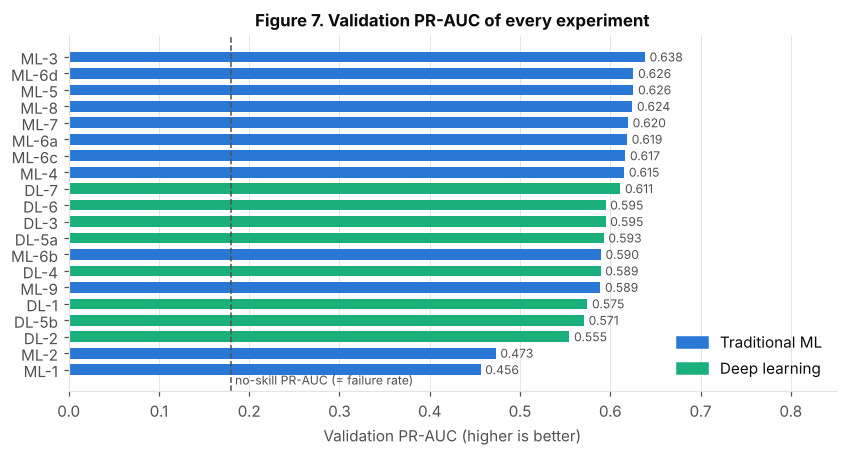

In [48]:
fig, ax = plt.subplots(figsize=(9, 4.2))
order = exp_table.sort_values("val_pr_auc")
colors = [BLUE if f == "traditional" else AQUA for f in order["family"]]
bars = ax.barh(order["run"], order["val_pr_auc"], color=colors, height=0.65)
ax.bar_label(bars, fmt="%.3f", padding=3, fontsize=8, color=INK_2)
ax.axvline(y_val.mean(), color=INK_2, linestyle="--", linewidth=1)
ax.text(y_val.mean() + 0.005, -0.9, "no-skill PR-AUC (= failure rate)", fontsize=8, color=INK_2)
ax.set_xlim(0, 0.85)
ax.set_xlabel("Validation PR-AUC (higher is better)")
ax.set_title("Figure 7. Validation PR-AUC of every experiment")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=BLUE, label="Traditional ML"), Patch(color=AQUA, label="Deep learning")],
          loc="lower right")
save_fig("fig07_experiment_pr_auc")

**Interpretation.** Three tiers are visible. Logistic regression (ML-1, ML-2) sits far below
everything else at about 0.46 to 0.47. The neural networks occupy a middle band from about 0.55
(the unregularised DL-2) to 0.61 (DL-7 with district embeddings). The tree ensembles form the top
tier between about 0.59 and 0.64, led by the random forest (ML-3). Within each family, the
differences produced by tuning, imbalance handling and feature changes are small (a few
hundredths) compared with the gap *between* families. Every model is far above the no-skill
level of 0.18.

### 7.2 Bias and variance across experiments

Plotting each run's training score against its validation score places it in the bias–variance
picture. Runs near the diagonal generalise as well as they fit (low variance); if they also sit
low on both axes, they are **underfitting** (high bias). Runs far to the right of the diagonal fit
the training data much better than unseen data (high variance, **overfitting**).

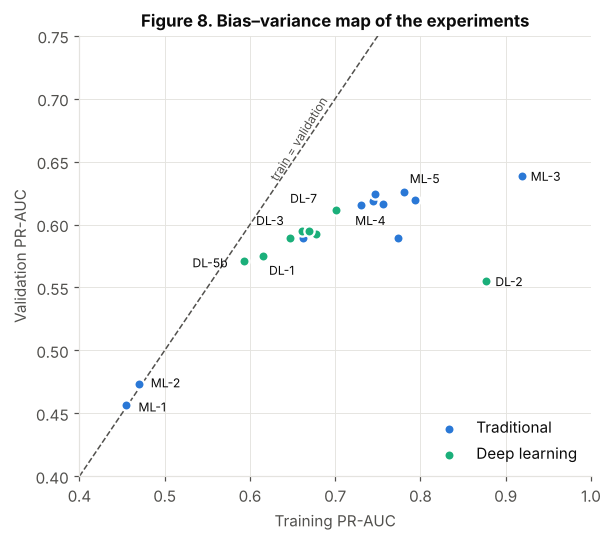

In [49]:
LABELLED_RUNS = ["ML-1", "ML-2", "ML-3", "ML-4", "ML-5", "DL-1", "DL-2", "DL-3", "DL-5b", "DL-7"]
LABEL_OFFSETS = {"ML-1": (8, -4), "ML-2": (8, -2), "ML-4": (-4, -13), "ML-5": (4, 6), "DL-1": (4, -12),
                 "DL-3": (-30, 4), "DL-5b": (-34, -4), "DL-7": (-30, 5)}
fig, ax = plt.subplots(figsize=(6, 5.2))
for family, colour in [("traditional", BLUE), ("deep learning", AQUA)]:
    sub = exp_table[(exp_table["family"] == family) & (exp_table["threshold"] == 0.5)]
    ax.scatter(sub["train_pr_auc"], sub["val_pr_auc"], s=45, color=colour, label=family.capitalize(),
               edgecolor="white", linewidth=1.5, zorder=3)
    for _, r in sub[sub["run"].isin(LABELLED_RUNS)].iterrows():
        ax.annotate(r["run"], (r["train_pr_auc"], r["val_pr_auc"]), textcoords="offset points",
                    xytext=LABEL_OFFSETS.get(r["run"], (6, -3)), fontsize=8, color=INK)
lims = [0.4, 1.0]
ax.plot(lims, lims, color=INK_2, linestyle="--", linewidth=1)
ax.text(0.62, 0.635, "train = validation", rotation=58, fontsize=8, color=INK_2)
ax.set_xlim(lims); ax.set_ylim(0.4, 0.75)
ax.set_xlabel("Training PR-AUC")
ax.set_ylabel("Validation PR-AUC")
ax.set_title("Figure 8. Bias–variance map of the experiments")
ax.legend(loc="lower right")
save_fig("fig08_bias_variance")

**Interpretation.** The map separates the experiments cleanly into the three regimes of the
bias–variance trade-off:

- **High bias:** logistic regression (ML-1, ML-2) lies on the diagonal but low down. It
  generalises perfectly because it learns too little; adding data or regularisation would not
  help, only a more expressive model would.
- **High variance:** the random forest (ML-3, training PR-AUC about 0.92) and the unregularised
  network (DL-2, about 0.88) lie far to the right. The difference between them is instructive:
  averaging hundreds of de-correlated trees keeps the forest's validation score the highest of
  all, while the single over-parameterised network loses validation performance as it memorises.
- **Balanced:** gradient boosting and the regularised networks (DL-3 to DL-7) sit in between,
  with moderate gaps of about 0.05 to 0.15.

The best validation score belongs to a high-variance model, which is unusual and is explained by
the spatial clustering of the data (Section 7.10 tests the consequence).

### 7.3 Learning curves

**Traditional models.** A learning curve trains the model on growing fractions of the training
data (3-fold cross-validation at each size) and plots training and cross-validated PR-AUC. The
shape of the two curves diagnoses the model: converging low curves mean high bias; a wide,
persistent gap means high variance; a validation curve still rising at full size means more data
would help.

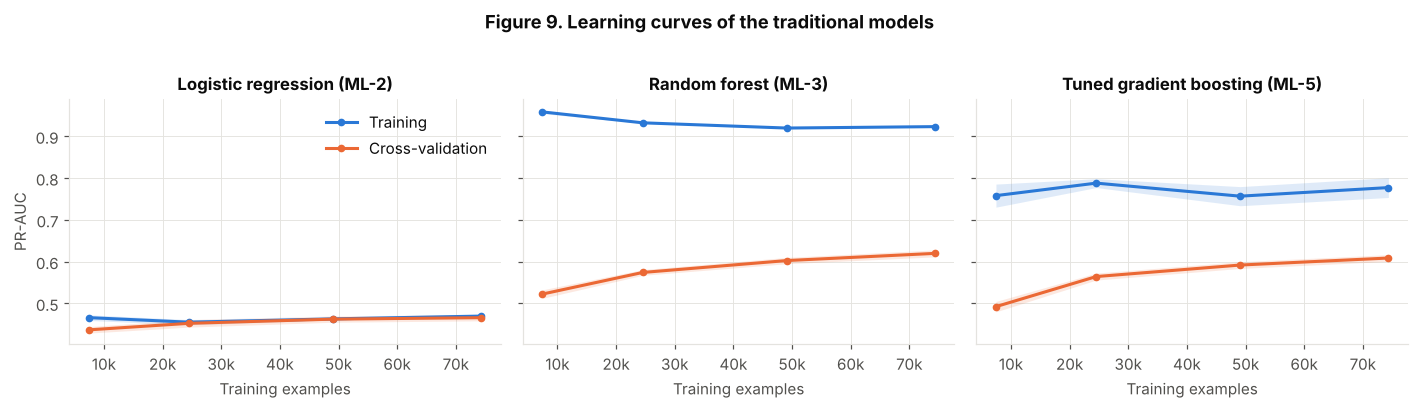

,train PR-AUC (full),CV PR-AUC (full),CV PR-AUC (10%)
Logistic regression (ML-2),0.470,0.466,0.437
Random forest (ML-3),0.923,0.620,0.522
Tuned gradient boosting (ML-5),0.777,0.609,0.492


In [50]:
from sklearn.model_selection import learning_curve
from sklearn.base import clone

curves = {}
for name, estimator in [("Logistic regression (ML-2)", ml2), ("Random forest (ML-3)", ml3),
                        ("Tuned gradient boosting (ML-5)", ml5)]:
    sizes, train_sc, cv_sc = learning_curve(
        clone(estimator), X_train, y_train, train_sizes=[0.1, 0.33, 0.66, 1.0],
        cv=StratifiedKFold(3, shuffle=True, random_state=SEED), scoring="average_precision", n_jobs=1)
    curves[name] = (sizes, train_sc, cv_sc)

fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
for ax, (name, (sizes, tr, cv)) in zip(axes, curves.items()):
    for scores_, colour, label in [(tr, BLUE, "Training"), (cv, ORANGE, "Cross-validation")]:
        ax.plot(sizes, scores_.mean(1), color=colour, linewidth=2, marker="o", markersize=4, label=label)
        ax.fill_between(sizes, scores_.mean(1) - scores_.std(1), scores_.mean(1) + scores_.std(1),
                        color=colour, alpha=0.15, linewidth=0)
    ax.set_title(name)
    ax.set_xlabel("Training examples")
    ax.xaxis.set_major_formatter(mtick.FuncFormatter(lambda v, _: f"{v/1000:.0f}k"))
axes[0].set_ylabel("PR-AUC")
axes[0].legend(loc="upper right")
fig.suptitle("Figure 9. Learning curves of the traditional models", fontweight="bold", y=1.02)
plt.tight_layout()
save_fig("fig09_learning_curves_ml")
pd.DataFrame({name: {"train PR-AUC (full)": tr.mean(1)[-1], "CV PR-AUC (full)": cv.mean(1)[-1],
                     "CV PR-AUC (10%)": cv.mean(1)[0]} for name, (s, tr, cv) in curves.items()}).T.round(3)

**Interpretation.** The three curves confirm the diagnosis from Figure 8.

- **Logistic regression:** the training and cross-validation curves meet at about 0.47 and stay
  flat. This is pure bias: the model has already learned all it can, and more data will not help.
- **Random forest:** training PR-AUC stays above 0.92 at every size, while cross-validated
  PR-AUC rises steadily from about 0.52 with 10% of the data to 0.62 with all of it. The wide gap
  is variance, but the validation curve is **still rising** at full size, so more data of the
  same kind would likely improve it further.
- **Gradient boosting:** a smaller gap (training about 0.78) with the same upward-sloping
  validation curve (about 0.49 to 0.61).

For both ensembles, more training data, not more model complexity, is the most promising lever.

**Deep learning models.** For the networks, the learning curve is the training history: loss and
PR-AUC on the training and validation sets after every epoch (the same curves are in
TensorBoard under `logs/dl`).

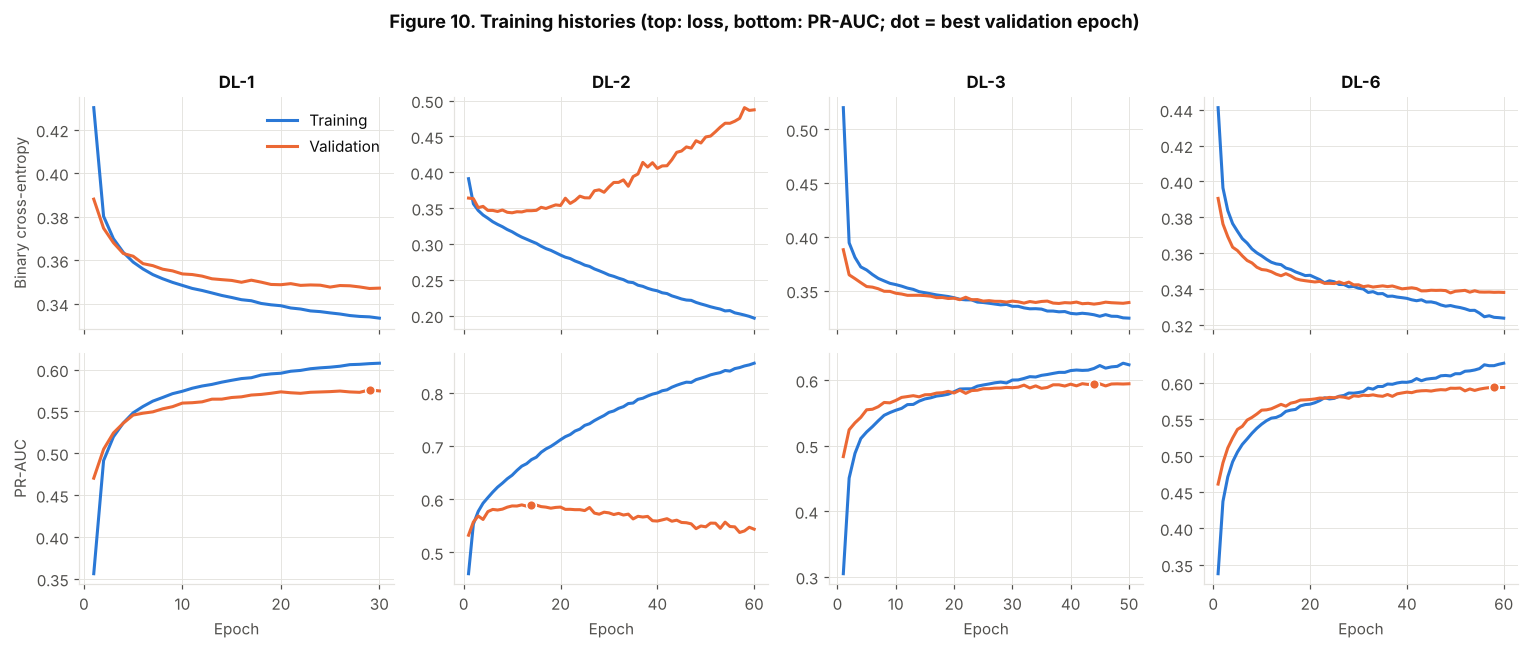

In [51]:
fig, axes = plt.subplots(2, 4, figsize=(14, 5.8), sharex="col")
for col, run in enumerate(["DL-1", "DL-2", "DL-3", "DL-6"]):
    h = HISTORIES[run]
    epochs = np.arange(1, len(h["loss"]) + 1)
    axes[0, col].plot(epochs, h["loss"], color=BLUE, linewidth=2, label="Training")
    axes[0, col].plot(epochs, h["val_loss"], color=ORANGE, linewidth=2, label="Validation")
    axes[1, col].plot(epochs, h["pr_auc"], color=BLUE, linewidth=2)
    axes[1, col].plot(epochs, h["val_pr_auc"], color=ORANGE, linewidth=2)
    best = int(np.argmax(h["val_pr_auc"]))
    axes[1, col].scatter(best + 1, h["val_pr_auc"][best], s=40, color=ORANGE, edgecolor="white", zorder=3)
    axes[0, col].set_title(run)
    axes[1, col].set_xlabel("Epoch")
axes[0, 0].set_ylabel("Binary cross-entropy")
axes[1, 0].set_ylabel("PR-AUC")
axes[0, 0].legend()
fig.suptitle("Figure 10. Training histories (top: loss, bottom: PR-AUC; dot = best validation epoch)",
             fontweight="bold", y=1.01)
plt.tight_layout()
save_fig("fig10_learning_curves_dl")

**Interpretation.** The four histories tell the deep learning story in one figure:

- **DL-1:** training and validation curves fall together and flatten, with a small and stable
  gap. Slight underfitting.
- **DL-2:** the classic overfitting signature. Validation loss bottoms out at epoch 10 and then
  climbs steeply while training loss keeps falling; validation PR-AUC peaks around epoch 14 and
  then declines.
- **DL-3:** dropout and batch normalisation keep the curves together for about 25 epochs; after
  that the training curve pulls slowly ahead, and early stopping restores the epoch-44 weights.
- **DL-6:** the embedding model behaves almost identically to DL-3, with `ReduceLROnPlateau`
  smoothing the later epochs.

### 7.4 Choosing the final models and their thresholds

One model from each family is carried forward: the traditional and deep learning runs with the
highest validation PR-AUC, excluding ML-8 (which uses the data-source shortcut). For each, the
decision threshold is set to the value that maximises F1 on the **validation** set. Only then is
the **test set** used, once, to compare them.

In [52]:
deployable = exp_table[(exp_table["run"] != "ML-8") & (exp_table["threshold"] == 0.5)]
BEST_ML_RUN = deployable[deployable["family"] == "traditional"].sort_values("val_pr_auc").iloc[-1]["run"]
BEST_DL_RUN = deployable[deployable["family"] == "deep learning"].sort_values("val_pr_auc").iloc[-1]["run"]
ML_PIPELINES = {"ML-1": ml1, "ML-2": ml2, "ML-3": ml3, "ML-4": ml4, "ML-5": ml5,
                "ML-6a": ml6a, "ML-6b": ml6b, "ML-6c": ml6c, "ML-7": ml7, "ML-9": ml9}
FEATURE_SET_OF = {"ML-1": RAW_FEATURES, "ML-7": RAW_FEATURES, "ML-9": LOCATION_FREE}


def dl_inputs(run_id, df):
    """Build the right model inputs for a deep learning run."""
    if run_id == "DL-7":
        return make_dataset(to_inputs7(df))
    if run_id == "DL-6":
        return make_dataset(to_inputs(df))
    return make_dataset(dl_prep.transform(xy(df, ENGINEERED_FEATURES)[0]).astype("float32"))


def predict(run_id, df):
    """Probability of 'not functional' for any final candidate."""
    if run_id.startswith("ML"):
        fs = FEATURE_SET_OF.get(run_id, ENGINEERED_FEATURES)
        return ML_PIPELINES[run_id].predict_proba(xy(df, fs)[0])[:, 1]
    return KERAS_MODELS[run_id].predict(dl_inputs(run_id, df), verbose=0).ravel()


FINAL = {"Traditional": BEST_ML_RUN, "Deep learning": BEST_DL_RUN}
THRESHOLDS = {name: f1_optimal_threshold(y_val, VAL_PROBS[run]) for name, run in FINAL.items()}
for name, run in FINAL.items():
    print(f"{name:<14} best run: {run:<6} validation PR-AUC {VAL_PROBS[run] is not None and average_precision_score(y_val, VAL_PROBS[run]):.3f} "
          f"| F1-optimal threshold {THRESHOLDS[name]:.3f}")

Traditional    best run: ML-3   validation PR-AUC 0.638 | F1-optimal threshold 0.484
Deep learning  best run: DL-7   validation PR-AUC 0.611 | F1-optimal threshold 0.249


In [53]:
from sklearn.metrics import confusion_matrix, accuracy_score, balanced_accuracy_score


def full_report(y_true, prob, threshold):
    pred = (prob >= threshold).astype(int)
    return {**scores(y_true, prob, threshold), "accuracy": accuracy_score(y_true, pred),
            "balanced_accuracy": balanced_accuracy_score(y_true, pred), "threshold": threshold}


TEST_PROBS = {name: predict(run, test_df) for name, run in FINAL.items()}
TEST_PROBS["Logistic regression (ML-2)"] = predict("ML-2", test_df)
final_test = pd.DataFrame({
    f"{name} ({FINAL.get(name, 'ML-2')})" if name in FINAL else name:
        full_report(y_test, TEST_PROBS[name], THRESHOLDS.get(name, 0.5))
    for name in TEST_PROBS}).T
final_test.to_csv(RESULTS_DIR / "final_test_metrics.csv")
final_test.round(3)

,roc_auc,pr_auc,recall,precision,f1,accuracy,balanced_accuracy,threshold
Traditional (ML-3),0.863,0.634,0.632,0.534,0.579,0.835,0.756,0.484
Deep learning (DL-7),0.850,0.611,0.690,0.454,0.548,0.796,0.755,0.249
Logistic regression (ML-2),0.779,0.478,0.701,0.333,0.452,0.695,0.697,0.500


**Interpretation.** On the untouched test set, the random forest (ML-3) is the best model on every
threshold-free metric: ROC-AUC about 0.86 and PR-AUC about 0.63, against about 0.85 and 0.61 for
the best network (DL-7) and 0.78 and 0.48 for the logistic regression baseline. Test scores are
within about 0.005 of the validation scores for both models, so the repeated use of the
validation set for model selection has not biased the comparison.

At their F1-optimal thresholds, the two final models make different trade-offs. The forest is
more precise (precision about 0.53, recall about 0.63, F1 about 0.58), while the network catches
more broken points but with more false alarms (recall about 0.69, precision about 0.45, F1 about
0.55). Balanced accuracy is almost identical (about 0.76 for both), and plain accuracy (about
0.84 against 0.80) mostly reflects how many working points each model leaves alone.

### 7.5 Confusion matrices on the test set

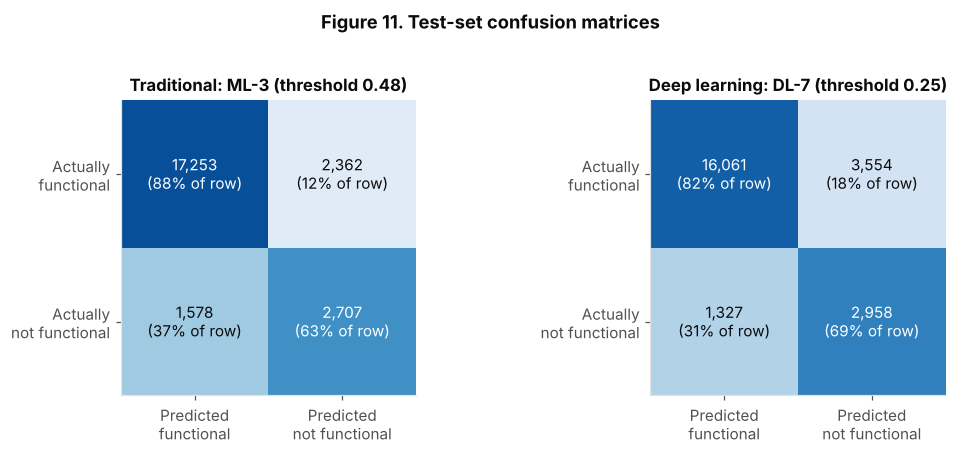

In [54]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, FINAL):
    pred = (TEST_PROBS[name] >= THRESHOLDS[name]).astype(int)
    cm = confusion_matrix(y_test, pred)
    row_share = cm / cm.sum(axis=1, keepdims=True)
    ax.imshow(row_share, cmap="Blues", vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm[i, j]:,}\n({row_share[i, j]:.0%} of row)", ha="center", va="center",
                    fontsize=10, color="white" if row_share[i, j] > 0.6 else INK)
    ax.set_xticks([0, 1], ["Predicted\nfunctional", "Predicted\nnot functional"])
    ax.set_yticks([0, 1], ["Actually\nfunctional", "Actually\nnot functional"])
    ax.grid(False)
    ax.set_title(f"{name}: {FINAL[name]} (threshold {THRESHOLDS[name]:.2f})")
fig.suptitle("Figure 11. Test-set confusion matrices", fontweight="bold", y=1.02)
plt.tight_layout()
save_fig("fig11_confusion_matrices")

**Interpretation.** Of the 4,285 broken points in the test set, the random forest finds 2,707
(63%) and misses 1,578 (37%). It raises 2,362 false alarms, about 12% of working points. The
network finds 2,958 (69%), missing 1,327, but at the cost of 3,554 false alarms (18% of working
points). The dominant error for both models is the **false negative**: a broken point predicted to
be working. In the application this is the costlier mistake, because a community keeps waiting
for a repair that nobody schedules, whereas a false alarm costs one wasted inspection visit.
Section 7.7 shows how the threshold can be moved to reflect that asymmetry.

### 7.6 ROC and precision–recall curves

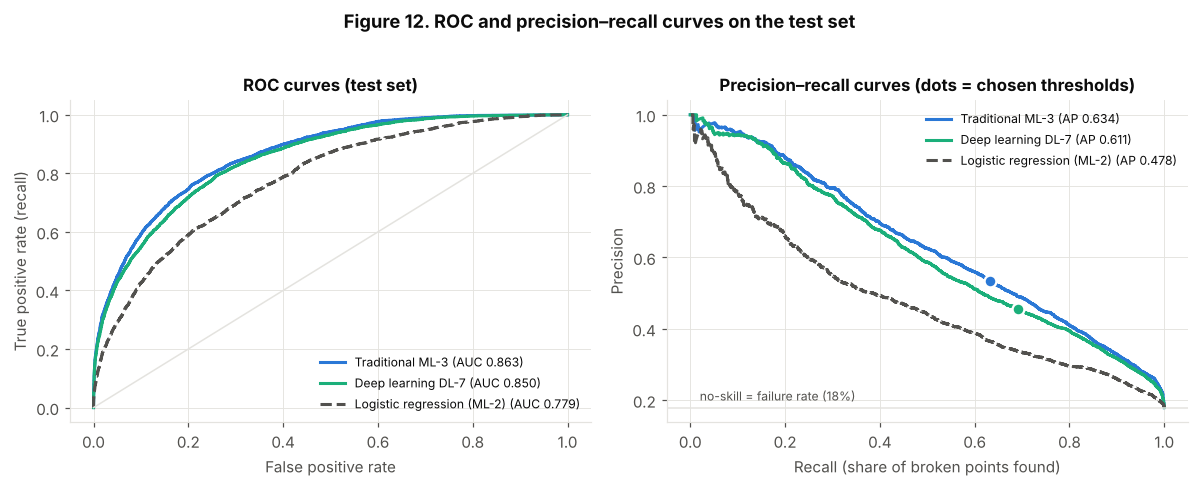

In [55]:
from sklearn.metrics import roc_curve

fig, axes = plt.subplots(1, 2, figsize=(11, 4.3))
curve_colors = {"Traditional": BLUE, "Deep learning": AQUA, "Logistic regression (ML-2)": INK_2}
for name, prob in TEST_PROBS.items():
    fpr, tpr, _ = roc_curve(y_test, prob)
    prec, rec, _ = precision_recall_curve(y_test, prob)
    label = f"{name} {FINAL.get(name, '')}".strip()
    style = "--" if "Logistic" in name else "-"
    axes[0].plot(fpr, tpr, color=curve_colors[name], linewidth=2, linestyle=style,
                 label=f"{label} (AUC {roc_auc_score(y_test, prob):.3f})")
    axes[1].plot(rec, prec, color=curve_colors[name], linewidth=2, linestyle=style,
                 label=f"{label} (AP {average_precision_score(y_test, prob):.3f})")
axes[0].plot([0, 1], [0, 1], color=GRID, linewidth=1)
axes[1].axhline(y_test.mean(), color=GRID, linewidth=1)
axes[1].text(0.02, y_test.mean() + 0.02, f"no-skill = failure rate ({y_test.mean():.0%})", fontsize=8, color=INK_2)
for name in FINAL:   # mark the chosen operating points
    pred = TEST_PROBS[name] >= THRESHOLDS[name]
    axes[1].scatter(recall_score(y_test, pred), precision_score(y_test, pred), s=60,
                    color=curve_colors[name], edgecolor="white", linewidth=1.5, zorder=4)
axes[0].set_xlabel("False positive rate"); axes[0].set_ylabel("True positive rate (recall)")
axes[0].set_title("ROC curves (test set)")
axes[1].set_xlabel("Recall (share of broken points found)"); axes[1].set_ylabel("Precision")
axes[1].set_title("Precision–recall curves (dots = chosen thresholds)")
axes[0].legend(loc="lower right", fontsize=8); axes[1].legend(loc="upper right", fontsize=8)
fig.suptitle("Figure 12. ROC and precision–recall curves on the test set", fontweight="bold", y=1.02)
plt.tight_layout()
save_fig("fig12_roc_pr_curves")

**Interpretation.** The ROC curves of the two final models almost overlap, and both lie well above
logistic regression. ROC-AUC looks flattering for every model, though, because the false positive
rate is computed over the large majority of working points, so even a sizeable number of false
alarms produces a small rate.

The precision–recall curves are more honest for this problem, because precision is computed only
over the points a model flags. They show clearly that the random forest dominates the network over
most of the recall range, and that both are far above the no-skill line at 0.18. They also show the
price of recall: finding 80% of broken points means accepting a precision of roughly 0.40, that
is, about three visits for every two broken points found. The dots mark the F1-optimal operating
points chosen on validation.

### 7.7 The threshold as an operational decision

A ministry does not need a probability; it needs a list of points to inspect. Ranking points by
predicted risk and inspecting from the top turns the model into an inspection plan. The table
shows what share of all broken points would be found if the inspection team could visit the
riskiest 10%, 20% or 30% of points, compared with visiting points at random.

In [56]:
def capture_at(prob, y_true, share):
    k = int(round(share * len(prob)))
    top = np.argsort(-prob)[:k]
    return y_true[top].sum() / y_true.sum(), y_true[top].mean()


rows = []
for share in [0.10, 0.20, 0.30]:
    row = {"inspect riskiest": f"{share:.0%} of points", "random inspection finds": f"{share:.0%}"}
    for name in FINAL:
        found, hit_rate = capture_at(TEST_PROBS[name], y_test, share)
        row[f"{name}: broken points found"] = f"{found:.0%}"
        row[f"{name}: share of visits that find a broken point"] = f"{hit_rate:.0%}"
    rows.append(row)
pd.DataFrame(rows).set_index("inspect riskiest")

,random inspection finds,Traditional: broken points found,Traditional: share of visits that find a broken point,Deep learning: broken points found,Deep learning: share of visits that find a broken point
inspect riskiest,,,,,
10% of points,10%,39%,70%,38%,69%
20% of points,20%,61%,55%,59%,52%
30% of points,30%,75%,45%,73%,43%


**Interpretation.** This is the most practical way to read the models. If a maintenance team can
visit only the **riskiest 10%** of water points, the random forest directs it to about **39% of
all broken points**, and about **7 visits in 10 find a broken point**, compared with fewer than 2
in 10 for random inspection. Visiting the riskiest 30% finds three-quarters of all broken points.
The network is only slightly behind. Framed this way, the choice of threshold is a resource
decision for the water authority, not a modelling decision.

### 7.8 Error analysis

Where do the final models go wrong? Errors on the test set are broken down by country,
technology family and age, using the traditional model at its chosen threshold.

In [57]:
err = test_df[["clean_country_name", "water_tech_category", "age_at_visit", TARGET]].copy()
err["water_tech_category"] = err["water_tech_category"].fillna("(missing)")
err["age_group"] = pd.cut(err["age_at_visit"], [-1, 5, 10, 20, 200], labels=["0-5", "6-10", "11-20", "20+"]
                          ).astype(str).replace("nan", "unknown")
for name in FINAL:
    err[f"pred_{name}"] = (TEST_PROBS[name] >= THRESHOLDS[name]).astype(int)


def group_errors(col, model="Traditional"):
    p = err[f"pred_{model}"]
    g = err.assign(tp=(p == 1) & (err[TARGET] == 1), fn=(p == 0) & (err[TARGET] == 1),
                   fp=(p == 1) & (err[TARGET] == 0)).groupby(col)
    out = pd.DataFrame({"points": g.size(), "failure_rate": g[TARGET].mean(),
                        "recall": g["tp"].sum() / (g["tp"].sum() + g["fn"].sum()),
                        "precision": g["tp"].sum() / (g["tp"].sum() + g["fp"].sum())})
    return out[out["points"] >= 100]


for col in ["clean_country_name", "water_tech_category", "age_group"]:
    print(f"\n=== Traditional model errors by {col} ===")
    print(group_errors(col).round(3).to_string())


=== Traditional model errors by clean_country_name ===
                    points  failure_rate  recall  precision
clean_country_name                                         
Ethiopia              3584         0.105   0.573      0.417
Kenya                 3251         0.088   0.331      0.413
Tanzania              2628         0.434   0.918      0.641
Uganda               14437         0.172   0.544      0.502

=== Traditional model errors by water_tech_category ===
                     points  failure_rate  recall  precision
water_tech_category                                         
(missing)              8808         0.139   0.487      0.469
Hand Pump              9729         0.218   0.701      0.530
Motorized Pump         1137         0.026   0.345      0.556
Public Tapstand        4216         0.215   0.676      0.630

=== Traditional model errors by age_group ===
           points  failure_rate  recall  precision
age_group                                         
0-5         

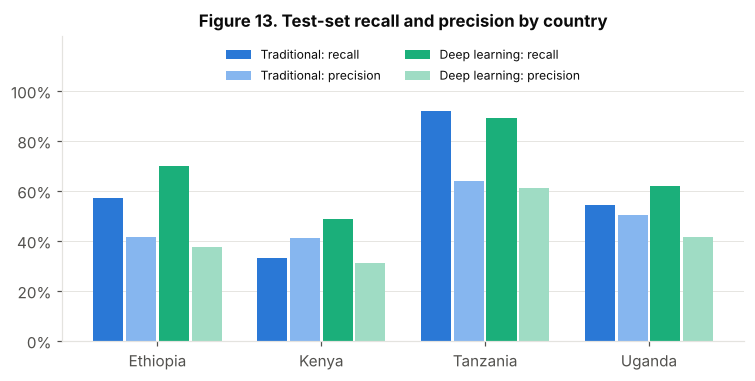

In [58]:
by_country = pd.concat({name: group_errors("clean_country_name", name)[["recall", "precision"]]
                        for name in FINAL}, axis=1)
fig, ax = plt.subplots(figsize=(8, 3.6))
x = np.arange(len(by_country))
w = 0.2
series = [(("Traditional", "recall"), BLUE, "Traditional: recall"),
          (("Traditional", "precision"), "#86b6ef", "Traditional: precision"),
          (("Deep learning", "recall"), AQUA, "Deep learning: recall"),
          (("Deep learning", "precision"), "#9fdcc4", "Deep learning: precision")]
for i, (key, colour, label) in enumerate(series):
    ax.bar(x + (i - 1.5) * w, by_country[key], width=w * 0.92, color=colour, label=label)
ax.set_xticks(x, by_country.index)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
ax.set_ylim(0, 1.22)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_title("Figure 13. Test-set recall and precision by country")
ax.legend(ncol=2, fontsize=8, loc="upper center")
ax.grid(axis="x", visible=False)
save_fig("fig13_errors_by_country")

**Interpretation.** Errors are far from uniform.

- **By country,** recall tracks the base rate. In Tanzania, where 43% of points are dry, the
  forest finds about 92% of broken points; in Kenya, where only 9% are dry, it finds only about
  33%. The models lean heavily on *where* a point is: in a low-failure country, a broken point
  looks like its many working neighbours and is missed.
- **By technology,** motorised pumps are the hardest case (recall about 0.35). They rarely fail
  (3%), so the model has seen few examples of failure.
- **By age,** recall rises from about 0.51 for points up to five years old to about 0.83 for
  points over 20. Young points that fail are the hardest to predict. This matches the World Bank
  finding that early failures in Tanzania are driven mainly by hydrogeological conditions such as
  low-yielding or drying wells, which are absent from WPdx data.

The network shows the same pattern with higher recall and lower precision everywhere, consistent
with its lower threshold.

### 7.9 Which features drive the predictions?

Permutation importance measures how much validation PR-AUC drops when one input column is
randomly shuffled, breaking its relationship with the label. It is computed on the original
columns (before one-hot encoding), so each bar is a feature a water engineer would recognise.
A 10,000-row sample of the validation set and five repeats keep the computation fast.

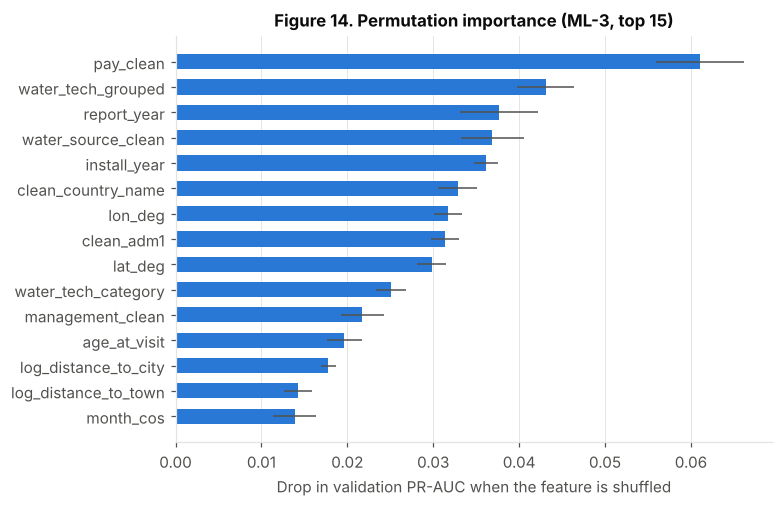

In [59]:
from sklearn.inspection import permutation_importance

sample_idx = val_df.sample(10_000, random_state=SEED).index
X_imp, y_imp = xy(val_df.loc[sample_idx], FEATURE_SET_OF.get(BEST_ML_RUN, ENGINEERED_FEATURES))
imp = permutation_importance(ML_PIPELINES[BEST_ML_RUN], X_imp, y_imp, scoring="average_precision",
                             n_repeats=5, random_state=SEED, n_jobs=1)
importance = (pd.DataFrame({"feature": X_imp.columns, "mean": imp.importances_mean, "std": imp.importances_std})
              .sort_values("mean", ascending=True).tail(15))
importance.to_csv(RESULTS_DIR / "permutation_importance.csv", index=False)

fig, ax = plt.subplots(figsize=(7, 4.8))
ax.barh(importance["feature"], importance["mean"], xerr=importance["std"], color=BLUE, height=0.6,
        error_kw={"ecolor": INK_2, "elinewidth": 1})
ax.set_xlabel("Drop in validation PR-AUC when the feature is shuffled")
ax.set_title(f"Figure 14. Permutation importance ({BEST_ML_RUN}, top 15)")
ax.grid(axis="y", visible=False)
save_fig("fig14_permutation_importance")

**Interpretation.** The most important feature is **payment** (`pay_clean`), followed by
**technology**, **visit year**, **water source** and **install year**. The physical and management
attributes (technology, source, age, payment, management) are exactly those emphasised in the
handpump-sustainability literature, which is reassuring.

Two caveats temper the reading. First, `pay_clean` is 64% missing, and categories such as
"Blank/unknown" are partly records of *how a survey filled in the form*, so some of its importance
is survey-specific. Second, location is spread across several correlated columns (country, region,
latitude and longitude). Permutation importance shuffles one column at a time, so the combined
importance of location is larger than any single bar suggests. Together with the high rank of
visit year, this confirms the ML-8 finding that survey identity is learned through proxies.

### 7.10 Transfer test: Rwanda

Both final models are now applied, unchanged and with their validation-chosen thresholds, to
Rwanda's 5,801 labelled water points, a country that played no part in training or tuning.
Rwanda's regions are unknown to the models (they fall into the "unknown/infrequent" category),
so the models must rely on technology, age, management, distances and coordinates.

In [60]:
RWA_PROBS = {name: predict(run, rwanda) for name, run in FINAL.items()}
RWA_PROBS["Logistic regression (ML-2)"] = predict("ML-2", rwanda)
RWA_PROBS["Location-free boosting (ML-9)"] = predict("ML-9", rwanda)
TEST_PROBS["Location-free boosting (ML-9)"] = predict("ML-9", test_df)
THRESHOLDS["Location-free boosting (ML-9)"] = f1_optimal_threshold(y_val, VAL_PROBS["ML-9"])
transfer = pd.DataFrame({
    (f"{name} ({FINAL[name]})" if name in FINAL else name):
        full_report(y_rwa, RWA_PROBS[name], THRESHOLDS.get(name, 0.5))
    for name in RWA_PROBS}).T
transfer.to_csv(RESULTS_DIR / "rwanda_transfer_metrics.csv")

comparison = pd.DataFrame({
    "test PR-AUC": [average_precision_score(y_test, TEST_PROBS[n]) for n in RWA_PROBS],
    "Rwanda PR-AUC": [average_precision_score(y_rwa, RWA_PROBS[n]) for n in RWA_PROBS],
    "test ROC-AUC": [roc_auc_score(y_test, TEST_PROBS[n]) for n in RWA_PROBS],
    "Rwanda ROC-AUC": [roc_auc_score(y_rwa, RWA_PROBS[n]) for n in RWA_PROBS],
    "Rwanda recall": transfer["recall"].values, "Rwanda precision": transfer["precision"].values,
    "Rwanda mean predicted risk": [RWA_PROBS[n].mean() for n in RWA_PROBS],
}, index=transfer.index)
print(f"Actual Rwanda failure rate: {y_rwa.mean():.1%} (no-skill PR-AUC)")
comparison.round(3)

Actual Rwanda failure rate: 14.8% (no-skill PR-AUC)


,test PR-AUC,Rwanda PR-AUC,test ROC-AUC,Rwanda ROC-AUC,Rwanda recall,Rwanda precision,Rwanda mean predicted risk
Traditional (ML-3),0.634,0.206,0.863,0.600,0.000,0.000,0.224
Deep learning (DL-7),0.611,0.200,0.850,0.566,0.021,0.240,0.032
Logistic regression (ML-2),0.478,0.165,0.779,0.538,0.039,0.145,0.344
Location-free boosting (ML-9),0.592,0.202,0.837,0.638,0.007,0.167,0.068


**Interpretation.** Transfer to Rwanda **fails**. The random forest's ROC-AUC falls from about 0.86
on the test set to about 0.60, and its PR-AUC from about 0.63 to about 0.21, barely above
Rwanda's no-skill level of 0.15. At the threshold chosen on validation, it flags almost no
Rwandan points at all, so recall is close to zero. The network does no better (ROC-AUC about 0.57,
average predicted risk only about 3% against an actual failure rate of 15%). The location-free
model (ML-9) ranks Rwandan points slightly better (ROC-AUC about 0.64) but is still far from useful.

The models are therefore well calibrated *within* the four countries they were trained on, but
they do not generalise to a new country, even a neighbouring one. The next table shows why.

**Why does transfer fail? A diagnosis.** The table below compares the training countries and
Rwanda on the attributes the models rely on most.

In [61]:
def profile(df, label):
    tech = df["water_tech_category"].fillna("(missing)")
    out = {"points": len(df), "failure rate": df[TARGET].mean()}
    for t in ["Hand Pump", "Public Tapstand", "(missing)"]:
        out[f"share: {t}"] = (tech == t).mean()
        out[f"failure rate: {t}"] = df.loc[tech == t, TARGET].mean()
    for col in ["management_clean", "pay_clean", "install_year"]:
        out[f"missing: {col}"] = df[col].isna().mean()
    out["failure rate | install year missing"] = df.loc[df["install_year"].isna(), TARGET].mean()
    out["failure rate | install year known"] = df.loc[df["install_year"].notna(), TARGET].mean()
    return pd.Series(out, name=label)


shift = pd.concat([profile(train_df, "Training countries"), profile(rwanda, "Rwanda")], axis=1)
shift.to_csv(RESULTS_DIR / "rwanda_distribution_shift.csv")
shift.style.format(lambda v: f"{v:,.0f}" if v > 1 else f"{v:.1%}")

,Training countries,Rwanda
points,"111,530","5,801"
failure rate,17.9%,14.8%
share: Hand Pump,40.4%,6.9%
failure rate: Hand Pump,21.8%,10.3%
share: Public Tapstand,17.7%,49.5%
failure rate: Public Tapstand,20.9%,23.7%
share: (missing),37.0%,43.5%
failure rate: (missing),14.3%,5.3%
missing: management_clean,16.8%,96.4%
missing: pay_clean,63.7%,98.6%


**Interpretation.** Rwanda differs from the training countries in two distinct ways, and both
break the models.

1. **Covariate shift (different inputs).** Rwanda's records are dominated by public tapstands on
   gravity-fed piped schemes (about half of points) and hand pumps are rare (about 7%), whereas
   hand pumps are the most common technology in training. Management and payment, two of the most
   important features, are missing for 96% and 99% of Rwandan points. The models are being asked
   about water points unlike the ones they learned from, with their most informative fields blank.
2. **Concept shift (different relationships).** Even where the inputs overlap, the relationships
   differ. In Rwanda, tapstands fail more than twice as often as hand pumps (about 24% against
   10%), while in training the two fail at similar rates. In training, a missing install year
   signals lower risk; in Rwanda it carries no signal at all (about 15% failure either way). A
   tapstand in Rwanda fails when the *scheme* behind it fails, a different mechanism from a worn
   hand pump.

Neither problem can be fixed by a better algorithm trained on the same data. Transfer would
require labelled Rwandan data (even a few hundred points for fine-tuning or re-calibration), or
features describing piped schemes. This is the most important limitation of the project and is
discussed further in Section 8 and in the report.

### 7.11 Saving the final models

The best traditional pipeline (preprocessing and model together) is saved with `joblib`, and the
best Keras model in the native `.keras` format, together with the preprocessing objects it needs.
Both files go into `models/` and are uploaded to the project's Google Drive folder.

In [62]:
import joblib

MODEL_DIR = Path("models")
MODEL_DIR.mkdir(exist_ok=True)
joblib.dump(ML_PIPELINES[BEST_ML_RUN], MODEL_DIR / "best_traditional_model.joblib", compress=3)
KERAS_MODELS[BEST_DL_RUN].save(MODEL_DIR / "best_deep_learning_model.keras")
dl_preprocessing = ({"type": "one-hot matrix", "preprocessor": dl_prep} if BEST_DL_RUN not in ("DL-6", "DL-7") else
                    {"type": "embedding inputs", "numeric_preprocessor": emb_num_prep if BEST_DL_RUN == "DL-6" else num_prep7,
                     "encoders": emb_encoders if BEST_DL_RUN == "DL-6" else encoders7})
joblib.dump(dl_preprocessing, MODEL_DIR / "best_deep_learning_preprocessing.joblib")
with open(MODEL_DIR / "model_card.json", "w") as fh:
    json.dump({"traditional_run": BEST_ML_RUN, "deep_learning_run": BEST_DL_RUN,
               "thresholds": THRESHOLDS, "features": ENGINEERED_FEATURES,
               "positive_class": "not_functional (status_id == 'No')", "seed": SEED}, fh, indent=2)

reloaded = joblib.load(MODEL_DIR / "best_traditional_model.joblib")
assert np.allclose(reloaded.predict_proba(X_test.head(100))[:, 1], TEST_PROBS["Traditional"][:100])
reloaded_dl = tf.keras.models.load_model(MODEL_DIR / "best_deep_learning_model.keras")
assert np.allclose(reloaded_dl.predict(dl_inputs(BEST_DL_RUN, test_df.head(100)), verbose=0).ravel(),
                   TEST_PROBS["Deep learning"][:100], atol=1e-5)
for f in sorted(MODEL_DIR.iterdir()):
    print(f"{f.name:<42} {f.stat().st_size/1e6:6.2f} MB")

best_deep_learning_model.keras               0.99 MB
best_deep_learning_preprocessing.joblib      0.02 MB
best_traditional_model.joblib               62.13 MB
model_card.json                              0.00 MB


## 8. Conclusions

### What was asked, and what was found

This notebook asked whether the recorded attributes of a rural water point can predict whether it
has water, using about 159,000 labelled WPdx+ records from Uganda, Ethiopia, Kenya and Tanzania,
with Rwanda held out entirely.

1. **Within the training countries, yes, to a useful degree.** The best model, a random forest,
   reaches a test ROC-AUC of about 0.86 and PR-AUC of about 0.63 (no-skill 0.18). Ranking points by
   its predicted risk and inspecting the riskiest 10% would find about 39% of all broken points,
   with roughly 7 in 10 visits finding a broken point.
2. **Tree ensembles beat neural networks on this tabular data.** The best network (entity
   embeddings including the district) reached a test PR-AUC of about 0.61 against 0.63 for the
   forest, at higher training cost and lower interpretability. This matches published benchmark
   evidence that tree-based models remain stronger on medium-sized tabular datasets.
3. **Imbalance is best handled at the decision threshold.** Class weights, undersampling and SMOTE
   moved the operating point but did not improve ranking quality (undersampling made it worse).
   Training on the real distribution and choosing the threshold on validation gave the best F1.
4. **Much of the signal is local and survey-specific.** Location and visit year are among the most
   important inputs, the data-contributor column adds nothing once they are present (ML-8), and the
   forest's best-in-class validation score coexists with heavy overfitting of the training set.
5. **The models do not transfer to a new country.** On Rwanda, ROC-AUC falls to about 0.60 and the
   models flag almost no broken points, because Rwanda's water points are a different mix
   (piped-scheme tapstands rather than hand pumps), its most informative fields are missing, and the
   relationships between features and failure are different.

### Bias–variance summary

Logistic regression underfits (high bias): its training and validation scores are equal and low,
and its learning curve is flat. The random forest and the unregularised network overfit (high
variance): their training scores are far above validation. The forest tolerates this because
averaging de-correlated trees cancels much of the variance; the single network does not, and
dropout, batch normalisation and early stopping were needed to bring it back. The ensembles'
learning curves are still rising at full data size, so more training data is the most promising
route to better in-distribution performance.

### Limitations

- **Label noise:** the detailed status field contradicts the basic one for about 48,600 points, and
  the basic `status_id` records a single visit, which may coincide with a temporary or seasonal
  outage.
- **Optimistic random split:** neighbouring points from the same survey appear in both training and
  test sets, which rewards memorisation of local clusters. The Rwanda result shows the cost.
- **Survey design as a hidden variable:** what gets recorded, and how, varies by contributor and
  campaign; the models partly learn these conventions.
- **Missing physical drivers:** groundwater depth, geology, rainfall, spare-parts supply chains
  and the condition of piped schemes are not in WPdx, yet the literature identifies them as key
  causes of failure, especially early failure.

### Future work

- Evaluate with **spatially grouped cross-validation** (holding out whole districts) to obtain
  honest estimates for unseen areas.
- Add **external geospatial covariates** (rainfall, groundwater productivity maps, terrain) that
  exist for every country, to give models transferable physical signals.
- **Adapt to new countries with a small labelled sample**, for example by re-calibrating thresholds
  or fine-tuning the embedding network on a few hundred Rwandan points.
- Model **scheme-level failure** for piped systems, where taps fail together because the scheme
  behind them fails.
- Use repeated observations of the same point (WPdx history) to predict **future** failure rather
  than current status.

### Experiment logs

All runs are logged under `logs/`. In Colab, the cell below opens TensorBoard inside the notebook:
the **HParams** tab shows every experiment's hyperparameters and metrics (the source of the
experiment table), and the **Scalars** tab shows the per-epoch training curves of the deep learning
runs.

In [63]:
import sys
if "google.colab" in sys.modules:
    get_ipython().run_line_magic("load_ext", "tensorboard")
    get_ipython().run_line_magic("tensorboard", "--logdir logs")
else:
    print("Run `tensorboard --logdir logs` in a terminal to browse the experiment logs.")
print(f"Logged runs: {len(EXPERIMENTS)} | figures saved: {len(list(FIG_DIR.glob('*.png')))} | "
      f"result tables: {sorted(p.name for p in RESULTS_DIR.glob('*.csv'))}")

Run `tensorboard --logdir logs` in a terminal to browse the experiment logs.
Logged runs: 20 | figures saved: 14 | result tables: ['experiment_table.csv', 'final_test_metrics.csv', 'permutation_importance.csv', 'rwanda_distribution_shift.csv', 'rwanda_transfer_metrics.csv']
